# OpenMP : étude de performance

## Utilisation d'un LLM

J'ai utilisé une (Claude Sonnet 5.5) pendant ce travail. Voici à quoi elle m'a servi :
- Compléter mon texte : j'ai rédigé mes analyses des parties 1 à 3 (sauf la 3.4), et l'assistant y a ajouté les valeurs chiffrées et les calculs de facteurs (rapports de temps, speedups, pourcentages de la borne théorique) à partir de mes fichiers de mesures.
- Corriger et reformuler : orthographe, accents, formulations et chiffres.
- Relire : il m'a signalé des aspects que je n'avais pas traités.
- Répondre à mes questions sur des résultats que je ne m'expliquais pas (cache, bande passante, limite du speedup, précision du `half`).
- Configurer la lecture et l'écriture des données : il m'a aidé à mettre en place le stockage des mesures (le classeur `mesures.xlsx`, l'ajout des résultats après chaque lancement, et la reprise sans doublons).

## Environnement expérimental

| | |
|---|---|
| Processeur | Intel Core i5-10500H @ 2.5 GHz, 6 cœurs physiques / 12 threads (hyperthreading) |
| Caches | L2 : 256 Ko par cœur (1.5 Mo au total), L3 : 12 Mo partagé |
| Mémoire | 8 Go de RAM (7.8 Go utilisables) |
| Système | Windows 11 Famille |
| Compilateur | g++ 15.1.0 (MinGW-Builds, posix-seh) |
| Options | `-fopenmp -O3 -march=native` (`-O3 -march=native` seul pour le séquentiel de la partie 2) |

**Méthodologie** : chaque configuration est lancée au moins 10 fois par un script Python (bibliothèque `subprocess`), sauf à 10^12 pas dans la partie 1 (voir 1.5). Chaque exécution écrit une ligne avec ses paramètres, qui est ajoutée à une feuille du classeur `mesures.xlsx` (une feuille par partie). Les tableaux donnent la moyenne ± l'écart-type, et les figures tracent la moyenne avec des barres d'erreur (écart-type) ainsi que les mesures individuelles. Le nombre de threads est un argument (`-C`) des programmes, sans recompilation. 

Pour reproduire : exécuter le notebook de haut en bas sur une machine disposant de g++ avec OpenMP et de Python (pandas, matplotlib, openpyxl).


## Organisation des fichiers

- `src/` : les sources C++ (`.cpp`) et `half.hpp`
- `bin/` : les exécutables compilés
- `donnees/` : le classeur `mesures.xlsx` (une feuille par partie)
- `enonce/` : le sujet de départ
- `docs/images/` : les figures de l'énoncé (reprises dans le `README.md`)
- `rapport_OpenMP.pdf` : la version PDF de ce rapport

## Stockage des mesures

Les mesures sont rangées dans le classeur `donnees/mesures.xlsx`, avec une feuille par partie. Chaque programme écrit ses résultats dans un petit fichier CSV temporaire, que la cellule suivante ajoute au classeur puis supprime. Les cellules de lancement ne relancent que les mesures qui manquent pour atteindre 10 répétitions.

In [ ]:
import csv
import os
import subprocess

import pandas as pd
from openpyxl import Workbook, load_workbook

NB_REPETITIONS = 10
FICHIER = "donnees/mesures.xlsx"

for dossier in ("src", "bin", "donnees"):
    os.makedirs(dossier, exist_ok=True)

# feuille du classeur : (CSV temporaire ecrit par les programmes, colonnes)
FEUILLES = {
    "partie1_pi": ("stats.csv", ["version", "nbcore", "num_steps", "runtime"]),
    "partie2_vecteur": ("stats_part2.csv", ["version", "nbcore", "N", "M", "size_mb", "runtime", "bandwidth"]),
    "partie3_fib": ("stats_part3.csv", ["version", "nbcore", "N", "runtime"]),
    "partie4_matrices": ("stats_part4.csv", ["version", "nbcore", "N", "M", "P", "runtime", "mflops"]),
    "partie5_chaine": ("stats_part5.csv", ["version", "nbcore", "N", "M", "P", "runtime", "mflops"]),
}


def charger(feuille):
    # lit une feuille du classeur (tableau vide si le classeur ou la feuille n'existe pas encore)
    if os.path.exists(FICHIER):
        try:
            return pd.read_excel(FICHIER, sheet_name=feuille)
        except ValueError:
            pass
    return pd.DataFrame(columns=FEUILLES[feuille][1])


def deja_faites(feuille, version, ncore, taille):
    # nombre de mesures deja presentes dans la feuille pour cette configuration
    d = charger(feuille)
    if d.empty:
        return 0
    return int(((d.iloc[:, 0] == version) & (d.iloc[:, 1] == ncore) & (d.iloc[:, 2] == taille)).sum())


def nettoyer_csv(feuille):
    # supprime un CSV temporaire oublie (par exemple ecrit par une cellule de test)
    csv_temp = FEUILLES[feuille][0]
    if os.path.exists(csv_temp):
        os.remove(csv_temp)


def nombre(x):
    try:
        return int(x)
    except ValueError:
        return float(x)


def fusionner(feuille):
    # ajoute a la feuille les lignes ecrites par les programmes dans le CSV temporaire, puis supprime ce CSV
    csv_temp, colonnes = FEUILLES[feuille]
    if not os.path.exists(csv_temp):
        return
    with open(csv_temp) as f:
        lignes = [r for r in csv.reader(f) if r]
    if os.path.exists(FICHIER):
        wb = load_workbook(FICHIER)
    else:
        wb = Workbook()
        wb.remove(wb.active)
    if feuille in wb.sheetnames:
        ws = wb[feuille]
    else:
        ws = wb.create_sheet(feuille)
        ws.append(colonnes)
    for r in lignes:
        ws.append([r[0]] + [nombre(x) for x in r[1:]])
    wb.save(FICHIER)
    os.remove(csv_temp)

## 1. Computing PI

### Référence séquentielle

Code de départ fourni (non modifié), utilise comme référence pour les comparaisons de performance dans les questions suivantes. Il calcule pi par intégration de 4/(1+x^2) sur [0,1] : chaque itération est indépendante, seule l'accumulation finale dans `sum` crée une dépendance.

In [1]:
from pathlib import Path

Path("src/1_0_pi_depart.cpp").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>

static long num_steps = 100000000;
double step;

int main (int argc, char** argv)
{

      // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atol( argv[ ++i ] );
            printf( "  User num_steps is %ld\n", num_steps );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }

	  int i;
	  double x, pi, sum = 0.0;

      step = 1.0/(double) num_steps;

      // Timer products.
      struct timeval begin, end;

      gettimeofday( &begin, NULL );

	  for (i=1;i<= num_steps; i++){
		  x = (i-0.5)*step;
		  sum = sum + 4.0/(1.0+x*x);
	  }

	  pi = step * sum;


      gettimeofday( &end, NULL );

      // Calculate time.
      double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );

      printf("\n pi with %ld steps is %lf in %lf seconds\n ",num_steps,pi,time);
}
""");

In [2]:
!g++ -O2 -Wall -o bin/1_0_pi_depart.exe src/1_0_pi_depart.cpp

In [3]:
!.\bin\1_0_pi_depart.exe -N 100000000

  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 0.206282 seconds
 


### Question 1.1 - For + critical

Parallélisation avec `#pragma omp parallel for private(x)` pour distribuer les itérations entre threads, et `#pragma omp critical` autour de la seule ligne qui met à jour `sum`. `x` est rendu privé à chaque thread pour éviter une seconde race condition, indépendante de celle sur `sum` (sans quoi plusieurs threads pourraient lire/écrire la même variable `x` en même temps). `critical` sérialise totalement l'accès à `sum` : un seul thread à la fois peut exécuter ce bloc.

In [4]:
from pathlib import Path

Path("src/1_1_pi_critical.cpp").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <fstream>
#include <omp.h>

static long long num_steps = 100000000;
double step;

int main (int argc, char** argv)
{
    int nb_threads = omp_get_max_threads();

    // Read command line arguments.
    for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atoll( argv[ ++i ] );
            printf( "  User num_steps is %lld\n", num_steps );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-num_threads" ) == 0 ) ) {
            nb_threads = atoi( argv[ ++i ] );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -num_threads (-C) <int>:    Number of OpenMP threads\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
    }

    omp_set_num_threads(nb_threads);

    long long i;
    double x, pi, sum = 0.0;

    step = 1.0/(double) num_steps;

    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );

    #pragma omp parallel for private(x)
    for (i=1; i<= num_steps; i++){
        x = (i-0.5)*step;
        #pragma omp critical
        {
            sum = sum + 4.0/(1.0+x*x);
        }
    }

    pi = step * sum;

    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
              1.0e-6 * ( end.tv_usec - begin.tv_usec );

    printf("\n pi with %lld steps is %lf in %lf seconds (threads=%d)\n ", num_steps, pi, time, nb_threads);

    std::ofstream csv("stats.csv", std::ios::app);
    csv << "critical," << nb_threads << "," << num_steps << "," << time << "\n";
    csv.close();
}
""");

In [5]:
!g++ -o bin/1_1_pi_critical src/1_1_pi_critical.cpp -fopenmp -O3 -march=native

In [6]:
!.\bin\1_1_pi_critical.exe -N 100000000 -C 1
!.\bin\1_1_pi_critical.exe -N 100000000 -C 4

  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 2.097087 seconds (threads=1)
 


  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 3.945646 seconds (threads=4)
 


### Question 1.2 - For + atomic

Même structure que 1.1, mais `#pragma omp atomic` remplace `critical` pour protéger l'unique instruction `sum = sum + ...`. En théorie plus léger qu'un verrou générique (`atomic` peut s'appuyer sur une instruction matérielle atomique), mais reste coûteux ici : j'ai demandé à une LLM la raison et elle m'a dit que cela est peut-être lié au fait qu'il n'existe pas d'instruction atomique matérielle pour l'addition en `double` sur x86, donc le compilateur émule l'opération via une boucle *compare-and-swap* (CAS) qui peut échouer et redémarrer sous forte contention.

In [7]:
from pathlib import Path

Path("src/1_2_pi_atomic.cpp").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <fstream>
#include <omp.h>

static long long num_steps = 100000000;
double step;

int main (int argc, char** argv)
{
    int nb_threads = omp_get_max_threads();

    // Read command line arguments.
    for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atoll( argv[ ++i ] );
            printf( "  User num_steps is %lld\n", num_steps );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-num_threads" ) == 0 ) ) {
            nb_threads = atoi( argv[ ++i ] );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -num_threads (-C) <int>:    Number of OpenMP threads\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
    }

    omp_set_num_threads(nb_threads);

    long long i;
    double x, pi, sum = 0.0;

    step = 1.0/(double) num_steps;

    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );

    #pragma omp parallel for private(x)
    for (i=1; i<= num_steps; i++){
        x = (i-0.5)*step;
        #pragma omp atomic
        sum = sum + 4.0/(1.0+x*x);
    }

    pi = step * sum;

    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
              1.0e-6 * ( end.tv_usec - begin.tv_usec );

    printf("\n pi with %lld steps is %lf in %lf seconds (threads=%d)\n ", num_steps, pi, time, nb_threads);

    std::ofstream csv("stats.csv", std::ios::app);
    csv << "atomic," << nb_threads << "," << num_steps << "," << time << "\n";
    csv.close();
}
""");

In [8]:
!g++ -o bin/1_2_pi_atomic src/1_2_pi_atomic.cpp -fopenmp -O3 -march=native

In [9]:
!.\bin\1_2_pi_atomic.exe -N 100000000 -C 1
!.\bin\1_2_pi_atomic.exe -N 100000000 -C 4

  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 1.365914 seconds (threads=1)
 


  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 9.483299 seconds (threads=4)
 


### Question 1.3 - For + reduction

Clause `reduction(+:sum)` ajoutée sur le `#pragma omp parallel for`. OpenMP donne à chaque thread sa propre copie privée de `sum` (initialisée à l'élément neutre, 0 pour `+`). Chaque thread accumule dans sa copie sans aucune synchronisation pendant la boucle, puis OpenMP fusionne automatiquement toutes les copies en une seule fois à la fin de la région parallèle.

In [10]:
from pathlib import Path

Path("src/1_3_pi_reduction.cpp").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <fstream>
#include <omp.h>

static long long num_steps = 100000000;
double step;

int main (int argc, char** argv)
{
    int nb_threads = omp_get_max_threads();

    // Read command line arguments.
    for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atoll( argv[ ++i ] );
            printf( "  User num_steps is %lld\n", num_steps );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-num_threads" ) == 0 ) ) {
            nb_threads = atoi( argv[ ++i ] );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -num_threads (-C) <int>:    Number of OpenMP threads\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
    }

    omp_set_num_threads(nb_threads);

    long long i;
    double x, pi, sum = 0.0;

    step = 1.0/(double) num_steps;

    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );

    #pragma omp parallel for private(x) reduction(+:sum)
    for (i=1; i<= num_steps; i++){
        x = (i-0.5)*step;
        sum = sum + 4.0/(1.0+x*x);
    }

    pi = step * sum;

    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
              1.0e-6 * ( end.tv_usec - begin.tv_usec );

    printf("\n pi with %lld steps is %lf in %lf seconds (threads=%d)\n ", num_steps, pi, time, nb_threads);

    std::ofstream csv("stats.csv", std::ios::app);
    csv << "reduction," << nb_threads << "," << num_steps << "," << time << "\n";
    csv.close();
}
""");

In [11]:
!g++ -o bin/1_3_pi_reduction src/1_3_pi_reduction.cpp -fopenmp -O3 -march=native

In [12]:
!.\bin\1_3_pi_reduction.exe -N 100000000 -C 1
!.\bin\1_3_pi_reduction.exe -N 100000000 -C 4

  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 0.228623 seconds (threads=1)
 


  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 0.068149 seconds (threads=4)
 


### Question 1.4 - Split manuel en N parties

Le tableau `[1, num_steps]` est découpé explicitement en `nb_threads` tranches contiguës (le dernier thread absorbe le reste de la division entière via un `if/else` explicite). Chaque thread accumule sa somme partielle dans sa propre case d'un tableau (`partial_sums[tid]`), sans jamais écrire dans une case partagée pendant le calcul.

In [13]:
from pathlib import Path

Path("src/1_4_pi_manual.cpp").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <fstream>
#include <vector>
#include <omp.h>

static long long num_steps = 100000000;
double step;

int main (int argc, char** argv)
{
    int nb_threads = omp_get_max_threads();

    // Read command line arguments.
    for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atoll( argv[ ++i ] );
            printf( "  User num_steps is %lld\n", num_steps );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-num_threads" ) == 0 ) ) {
            nb_threads = atoi( argv[ ++i ] );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -num_threads (-C) <int>:    Number of OpenMP threads\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
    }

    omp_set_num_threads(nb_threads);

    double pi, sum = 0.0;

    step = 1.0/(double) num_steps;

    // One slot per thread: each thread writes only to its own slot,
    // so no synchronization is needed during the parallel loop.
    std::vector<double> partial_sums(nb_threads, 0.0);

    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );

    #pragma omp parallel
    {
        int tid = omp_get_thread_num();

        // Split [1, num_steps] into nb_threads contiguous chunks.
        long long chunk = num_steps / nb_threads;
        long long start = (long long)tid * chunk + 1;
        long long stop;

        if (tid == nb_threads - 1) {
            // Last thread absorbs the remainder of the integer division.
            stop = num_steps;
        } else {
            stop = start + chunk - 1;
        }

        double local_sum = 0.0;
        for (long long i = start; i <= stop; i++) {
            double x = (i - 0.5) * step;
            local_sum += 4.0 / (1.0 + x * x);
        }

        partial_sums[tid] = local_sum;
    }

    for (int t = 0; t < nb_threads; t++) {
        sum += partial_sums[t];
    }

    pi = step * sum;

    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
              1.0e-6 * ( end.tv_usec - begin.tv_usec );

    printf("\n pi with %lld steps is %lf in %lf seconds (threads=%d)\n ", num_steps, pi, time, nb_threads);

    std::ofstream csv("stats.csv", std::ios::app);
    csv << "manual," << nb_threads << "," << num_steps << "," << time << "\n";
    csv.close();
}
""");

In [14]:
!g++ -o bin/1_4_pi_manual src/1_4_pi_manual.cpp -fopenmp -O3 -march=native

In [15]:
!.\bin\1_4_pi_manual.exe -N 100000000 -C 1
!.\bin\1_4_pi_manual.exe -N 100000000 -C 4
!.\bin\1_4_pi_manual.exe -N 100000000 -C 3

  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 0.198932 seconds (threads=1)
 


  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 0.060609 seconds (threads=4)
 


  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 0.058768 seconds (threads=3)
 


**Récapitulatif des premières mesures** (100 000 000 steps) :

| Version | 1 thread | 4 threads |
|---|---|---|
| séquentiel (référence) | 0.119 s | -- |
| critical | 1.466 s | 2.557 s |
| atomic | 0.919 s | 5.391 s |
| reduction | 0.099 s | 0.029 s |
| manual | 0.098 s | 0.037 s |

`reduction` et `manual` sont les seules stratégies qui accélèrent réellement le calcul.

### Question 1.5 - Évaluation de performance

Grille d'expériences retenue :

| num_steps | versions testées | nb_core | répétitions |
|---|---|---|---|
| 10^6, 10^8 | critical, atomic, reduction, manual | 1, 2, 4, 8 | 10 |
| 10^10 | reduction, manual | 1, 2, 4, 8 | 10 |
| 10^12 | manual | 1, 4, 8 | 1 (1 thread) / 5 (4 threads) / 5 (8 threads) |

`critical` et `atomic` sont exclus au-delà de 10^8 : leur exécution prendrait trop de temps et leur comportement déjà clairement établi (dégradation avec la contention).
À 10^12, seul `manual` est testé, sans le point à 2 threads (trop coûteux), et avec un seul run à 1 thread (23 min, pour avoir une référence T(1) et calculer le speedup : pas de répétition à ce point vu le coût).

In [ ]:
nettoyer_csv("partie1_pi")

nb_core = [1, 2, 4, 8]
binaries = {
    "critical": "./bin/1_1_pi_critical.exe",
    "atomic": "./bin/1_2_pi_atomic.exe",
    "reduction": "./bin/1_3_pi_reduction.exe",
    "manual": "./bin/1_4_pi_manual.exe",
}

# (num_steps, versions, nb_core, repetitions)
experiences = [
    (1000000, ["critical", "atomic", "reduction", "manual"], nb_core, NB_REPETITIONS),
    (100000000, ["critical", "atomic", "reduction", "manual"], nb_core, NB_REPETITIONS),
    # 10^10 : critical et atomic exclus (cf. discussion 1.5)
    (10000000000, ["reduction", "manual"], nb_core, NB_REPETITIONS),
    # 10^12 : manual seul, sans le point a 2 threads, et moins de repetitions car trop couteux (cf. 1.5)
    (1000000000000, ["manual"], [4, 8], 5),
    (1000000000000, ["manual"], [1], 1),
]

for num_steps, versions, cores, cible in experiences:
    for ncore in cores:
        for name in versions:
            for repeat in range(cible - deja_faites("partie1_pi", name, ncore, num_steps)):
                args = (binaries[name], "-C", str(ncore), "-N", str(num_steps))
                popen = subprocess.Popen(args, stdout=subprocess.PIPE)
                popen.wait()
            fusionner("partie1_pi")

### Question 1.6 - Figures de performance
#### Temps en fonction du nombre de threads

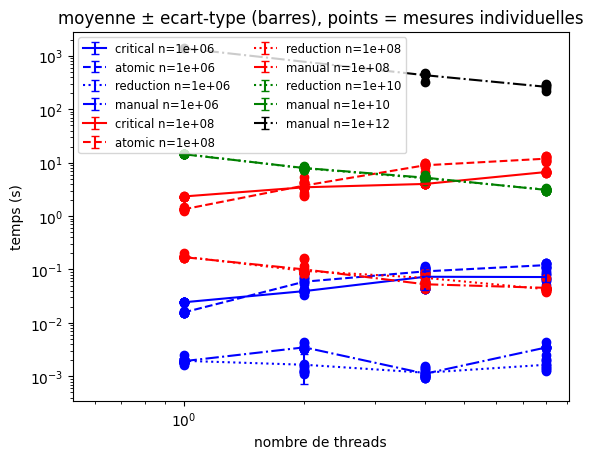

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie1_pi')

color_num_steps = {1000000 : "blue", 100000000 : "red", 10000000000 : "green", 1000000000000 : "black"}
version_linestyle = {"critical" : "solid", "atomic" : "dashed", "reduction" : "dotted", "manual" : "dashdot"}

for num_steps in df['num_steps'].unique():
    df_size = df[df['num_steps'] == int(num_steps)]

    for version, linestyle in version_linestyle.items():
        df_plot = df_size[df_size['version'] == version]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['num_steps','version','nbcore']).mean().reset_index()
        std_stats = df_plot.groupby(['num_steps','version','nbcore']).std().reset_index()

        plt.errorbar(mean_stats['nbcore'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                 linestyle=linestyle, color=color_num_steps[num_steps], label=f"{version} n={num_steps:.0e}")
        plt.yscale('log')
        plt.xscale('log')
        plt.scatter(df_plot['nbcore'], df_plot['runtime'], color=color_num_steps[num_steps])

plt.xlabel('nombre de threads')
plt.ylabel('temps (s)')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Strong Scaling

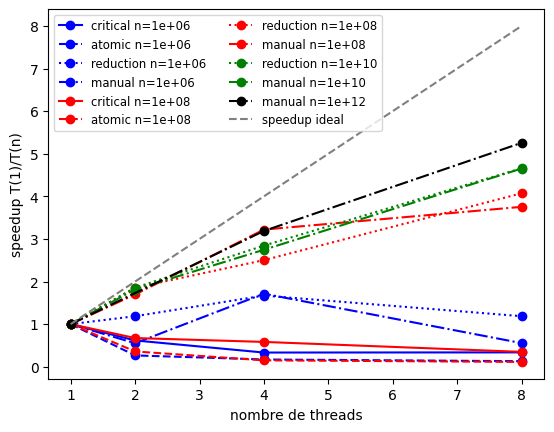

In [ ]:
fig_speedup = plt.figure()

for num_steps in df['num_steps'].unique():
    df_size = df[df['num_steps'] == int(num_steps)]

    for version, linestyle in version_linestyle.items():
        df_plot = df_size[df_size['version'] == version]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['num_steps','version','nbcore']).mean().reset_index()
        mean_stats = mean_stats.sort_values('nbcore')
        if 1 not in mean_stats['nbcore'].values:
            continue

        t1 = mean_stats[mean_stats['nbcore'] == 1]['runtime'].values[0]
        speedup = t1 / mean_stats['runtime']

        plt.plot(mean_stats['nbcore'], speedup, linestyle=linestyle,
                 color=color_num_steps[num_steps], marker='o', label=f"{version} n={num_steps:.0e}")

plt.plot([1,2,4,8], [1,2,4,8], linestyle='--', color='gray', label='speedup ideal')
plt.xlabel('nombre de threads')
plt.ylabel('speedup T(1)/T(n)')
plt.legend(fontsize='small', ncol=2)
plt.show()

### Question 1.7 - Discussion

`critical` et `atomic` sont contre-productifs et empirent avec plus de threads. À 10^8 steps, `critical` passe de 2.33s (1 thread) à 6.68s (8 threads), et `atomic` de 1.34s à 11.87s 
Les deux ralentissent quand on ajoute des threads, au lieu d'accélérer. Il doit s'agir du verrou/CAS qui coûte à lui seul plus cher (~23ns/itération à 1 thread) que tout le calcul séquentiel (~1-2ns) : ce surcoût fixe rend `critical`/`atomic` plus lents dès le départ, même sans concurrence. Plus de threads signifie plus de contention sur ce point d'accès unique, d'où l'aggravation.
Je me suis beaucoup interrogé sur la raison pour laquelle `atomic` dégrade plus vite que `critical` : j'ai demandé à une LLM et elle m'a expliqué cela par le fait sur `double`, il n'existe pas d'instruction atomique matérielle pour l'addition sur x86, donc le compilateur émule via une boucle compare-and-swap qui échoue et recommence de plus en plus souvent quand plusieurs threads martelent la même variable.

`reduction` et `manual` scalent de manière très similaire. À 10^8 steps, les deux passent d'environ 0.17s (1 thread) à environ 0.043-0.045s (8 threads), soit un speedup d'environ 3.7-4x, ce qui constitue une vraie accélération contrairement à `critical`/`atomic`. À 10^10 steps, le speedup s'améliore légèrement (environ 4.6x à 8 threads, de ~14.5s à ~3.1s), ce qui confirme que plus le travail utile est important, mieux le coût fixe de lancement de la région parallèle est amorti. Les deux stratégies donnent des temps quasiment identiques à toutes les tailles testées, ce qui confirme qu'elles implémentent la même idée (accumulation privée par thread puis fusion finale) : `reduction` le fait automatiquement, `manual` le fait explicitement, mais le résultat est le même.

À 10^6 steps, les mesures sont dominées par le bruit, pas par l'algorithme. Pour `reduction`/`manual`, l'écart-type est parfois du même ordre de grandeur que la moyenne elle-même (ex. `reduction` à 2 threads : moyenne 0.00165s, écart-type 0.00094s). À cette taille, le calcul utile dure une fraction de milliseconde, d'où l'intérêt de tester plusieurs ordres de grandeur de `num_steps` (en dessous d'un certain seuil de travail par thread, aucune conclusion fiable ne peut être tirée).

À 10^12 steps, `manual` passe de 1381.9s (1 thread, n=1) à 433.5s +/- 59.7 (4 threads, n=5) puis 263.0s +/- 30.7 (8 threads, n=5), soit un speedup d'environ 3.2x à 4 threads et 5.3x à 8 threads -- cohérent avec les speedups observés à 10^10, même si le point à 1 thread ne repose que sur une seule mesure (23 min pour ce run).

Conclusion : Dans mon cas, le choix de la stratégie de synchronisation prime largement sur le nombre de cœurs disponibles. Un mauvais choix de synchronisation (`critical`/`atomic` ici) rend une version parallèle plus lente que la version séquentielle, et ce d'autant plus que le nombre de threads augmente. À l'inverse, une stratégie qui minimise le partage pendant le calcul (`reduction`/`manual`) permet une accélération réelle, d'autant meilleure que le volume de travail par thread est important.

## 2. Matrix-Vector opération

### Question 2.1 - Code séquentiel

Code complété :

In [1]:
from pathlib import Path

Path("src/2_1_vector.cpp").write_text(r"""/*
//@HEADER
// ************************************************************************
//
//                        Kokkos v. 2.0
//              Copyright (2014) Sandia Corporation
//
// Under the terms of Contract DE-AC04-94AL85000 with Sandia Corporation,
// the U.S. Government retains certain rights in this software.
//
// Redistribution and use in source and binary forms, with or without
// modification, are permitted provided that the following conditions are
// met:
//
// 1. Redistributions of source code must retain the above copyright
// notice, this list of conditions and the following disclaimer.
//
// 2. Redistributions in binary form must reproduce the above copyright
// notice, this list of conditions and the following disclaimer in the
// documentation and/or other materials provided with the distribution.
//
// 3. Neither the name of the Corporation nor the names of the
// contributors may be used to endorse or promote products derived from
// this software without specific prior written permission.
//
// THIS SOFTWARE IS PROVIDED BY SANDIA CORPORATION "AS IS" AND ANY
// EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
// IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR
// PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL SANDIA CORPORATION OR THE
// CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL,
// EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO,
// PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR
// PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF
// LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING
// NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS
// SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
//
// Questions Contact  H. Carter Edwards (hcedwar@sandia.gov)
//
// ************************************************************************
//@HEADER
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>

#include <cmath>
#include <fstream>

void checkSizes( int &N, int &M, int &S, int &nrepeat );

int main( int argc, char* argv[] )
{
  int N = -1;         // number of rows 2^12
  int M = -1;         // number of columns 2^10
  int S = -1;         // total size 2^22
  int nrepeat = 100;  // number of repeats of the test

  // Read command line arguments.
  for ( int i = 0; i < argc; i++ ) {
    if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-Rows" ) == 0 ) ) {
      N = pow( 2, atoi( argv[ ++i ] ) );
      printf( "  User N is %d\n", N );
    }
    else if ( ( strcmp( argv[ i ], "-M" ) == 0 ) || ( strcmp( argv[ i ], "-Columns" ) == 0 ) ) {
      M = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User M is %d\n", M );
    }
    else if ( ( strcmp( argv[ i ], "-S" ) == 0 ) || ( strcmp( argv[ i ], "-Size" ) == 0 ) ) {
      S = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User S is %d\n", S );
    }
    else if ( strcmp( argv[ i ], "-nrepeat" ) == 0 ) {
      nrepeat = atoi( argv[ ++i ] );
    }
    else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
      printf( "  y^T*A*x Options:\n" );
      printf( "  -Rows (-N) <int>:      exponent num, determines number of rows 2^num (default: 2^12 = 4096)\n" );
      printf( "  -Columns (-M) <int>:   exponent num, determines number of columns 2^num (default: 2^10 = 1024)\n" );
      printf( "  -Size (-S) <int>:      exponent num, determines total matrix size 2^num (default: 2^22 = 4096*1024 )\n" );
      printf( "  -nrepeat <int>:        number of repetitions (default: 100)\n" );
      printf( "  -help (-h):            print this message\n\n" );
      exit( 1 );
    }
  }

  // Check sizes.
  checkSizes( N, M, S, nrepeat );

  // Allocate x,y,A
  auto y = (double*) std::malloc(N*sizeof(double));
  auto x = (double*) std::malloc(M*sizeof(double));
  auto A = (double*) std::malloc(N*M*sizeof(double));

  // Initialize y vector to 1.
  for (int i = 0; i < N; i++) {
    y[i] = 1.0;
  }

  // Initialize x vector to 1.
  for (int i = 0; i < M; i++) {
    x[i] = 1.0;
  }

  // Initialize A matrix, you can use a 1D index if you want a flat structure (i.e. a 1D array) e.g. j*M+i is the same than [j][i]
  for (int j = 0; j < N; j++) {
    for (int i = 0; i < M; i++) {
      A[j*M+i] = 1.0;
    }
  }

  // Timer products.
  struct timeval begin, end;

  gettimeofday( &begin, NULL );

  for ( int repeat = 0; repeat < nrepeat; repeat++ ) {
    // For each line i
        // Multiply the i lines with the vector x 
        // Sum the results of the previous step into a single variable
        double result = 0.0;
        for (int i = 0; i < N; i++) {
            double sum = 0.0;
            for (int j = 0; j < M; j++) {
                sum += A[i*M+j] * x[j];
            }
            // Multiply the result of the previous step with the i value of vector y
            // Sum the results of the previous step into a single variable (result)
            result += sum * y[i];
        }
        

    // Output result.
    if ( repeat == ( nrepeat - 1 ) ) {
      printf( "  Computed result for %d x %d is %lf\n", N, M, result );
    }

    const double solution = (double) N * (double) M;

    if ( result != solution ) {
      printf( "  Error: result( %lf ) != solution( %lf )\n", result, solution );
    }
  }

  gettimeofday( &end, NULL );

  // Calculate time.
  //double time = timer.seconds();
  double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );

  // Calculate bandwidth.
  // Each matrix A row (each of length M) is read once.
  // The x vector (of length M) is read N times.
  // The y vector (of length N) is read once.
  // double Gbytes = 1.0e-9 * double( sizeof(double) * ( 2 * M * N + N ) );
  double Gbytes = 1.0e-9 * double( sizeof(double) * ( M + M * N + N ) );

  // Print results (problem size, time and bandwidth in GB/s).
  printf( "  N( %d ) M( %d ) nrepeat ( %d ) problem( %g MB ) time( %g s ) bandwidth( %g GB/s )\n",
          N, M, nrepeat, Gbytes * 1000, time, Gbytes * nrepeat / time );
  std::ofstream("stats_part2.csv", std::ios::app) << "seq,1," << N << "," << M << "," << Gbytes * 1000 << "," << time << "," << Gbytes * nrepeat / time << "\n";

  std::free(A);
  std::free(y);
  std::free(x);

  return 0;
}

void checkSizes( int &N, int &M, int &S, int &nrepeat ) {
  // If S is undefined and N or M is undefined, set S to 2^22 or the bigger of N and M.
  if ( S == -1 && ( N == -1 || M == -1 ) ) {
    S = pow( 2, 22 );
    if ( S < N ) S = N;
    if ( S < M ) S = M;
  }

  // If S is undefined and both N and M are defined, set S = N * M.
  if ( S == -1 ) S = N * M;

  // If both N and M are undefined, fix row length to the smaller of S and 2^10 = 1024.
  if ( N == -1 && M == -1 ) {
    if ( S > 1024 ) {
      M = 1024;
    }
    else {
      M = S;
    }
  }

  // If only M is undefined, set it.
  if ( M == -1 ) M = S / N;

  // If N is undefined, set it.
  if ( N == -1 ) N = S / M;

  printf( "  Total size S = %d N = %d M = %d\n", S, N, M );

  // Check sizes.
  if ( ( S < 0 ) || ( N < 0 ) || ( M < 0 ) || ( nrepeat < 0 ) ) {
    printf( "  Sizes must be greater than 0.\n" );
    exit( 1 );
  }

  if ( ( N * M ) != S ) {
    printf( "  N * M != S\n" );
    exit( 1 );
  }
}
""")

7369

In [2]:
!g++ -o bin/2_1_vector src/2_1_vector.cpp -O3 -march=native

In [3]:
!.\bin\2_1_vector.exe -N 12 -M 10

  User N is 4096
  User M is 1024
  Total size S = 4194304 N = 4096 M = 1024
  Computed result for 4096 x 1024 is 4194304.000000
  N( 4096 ) M( 1024 ) nrepeat ( 100 ) problem( 33.5954 MB ) time( 0.744411 s ) bandwidth( 4.51302 GB/s )


### Question 2.2 - Évaluation de performance (séquentiel)

La dernière paire (16,15) est exclue car elle fait échouer le programme. Avec `-N 16 -M 15`, N = 65536 et M = 32768, donc S = N*M = 2^31, ce qui dépasse la capacité d'un `int` (max 2^31 - 1) : S déborde en valeur négative et `checkSizes` arrête l'exécution :

```
  User N is 65536
  User M is 32768
  Total size S = -2147483648 N = 65536 M = 32768
  Sizes must be greater than 0.
```

(Même sans ce débordement, `A` ferait 2^31 * 8 octets = 16 GiB, soit le double de la RAM de la machine utilisé.)

Chaque exécution affiche une ligne `N( .. ) M( .. ) ... time( .. s ) bandwidth( .. GB/s )` qui est parsée ici et ajoutée à la feuille `partie2_vecteur` du classeur `mesures.xlsx`.

In [ ]:
pairs = [(2, 1), (4, 3), (8, 7), (10, 9), (12, 11), (14, 13)]
nb_core = [1, 2, 4, 8]

In [ ]:
nettoyer_csv("partie2_vecteur")

for (n_exp, m_exp) in pairs:
    for repeat in range(NB_REPETITIONS - deja_faites("partie2_vecteur", "seq", 1, 2 ** n_exp)):
        args = ("./bin/2_1_vector.exe", "-N", str(n_exp), "-M", str(m_exp))
        popen = subprocess.Popen(args, stdout=subprocess.PIPE)
        popen.wait()
    fusionner("partie2_vecteur")

### Question 2.3 - Figures de performance (séquentiel)

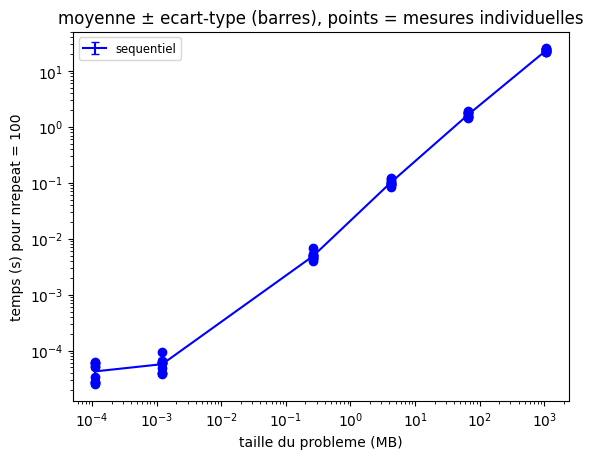

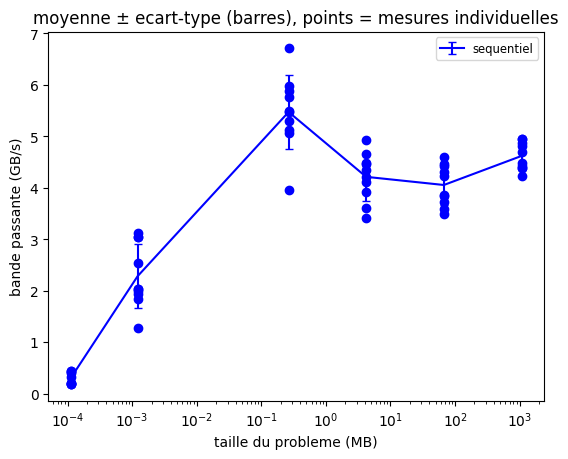

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

color_num_steps = {4: "blue", 16: "red", 256: "green", 1024: "purple", 4096: "orange", 16384: "black"}
version_linestyle = {"seq": "solid", "omp": "dashed", "simd": "dotted"}

df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie2_vecteur')
df_seq = df[df['version'] == 'seq']
mean_seq = df_seq.groupby(['N', 'M']).mean(numeric_only=True).reset_index().sort_values('size_mb')
std_seq = df_seq.groupby(['N', 'M']).std(numeric_only=True).reset_index().set_index(['N', 'M']).loc[list(zip(mean_seq['N'], mean_seq['M']))]

plt.errorbar(mean_seq['size_mb'], mean_seq['runtime'], yerr=std_seq['runtime'].values, capsize=3, linestyle="solid", color="blue", label="sequentiel")
plt.scatter(df_seq['size_mb'], df_seq['runtime'], color="blue")
plt.yscale('log')
plt.xscale('log')
plt.xlabel('taille du probleme (MB)')
plt.ylabel('temps (s) pour nrepeat = 100')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small')
plt.show()

plt.errorbar(mean_seq['size_mb'], mean_seq['bandwidth'], yerr=std_seq['bandwidth'].values, capsize=3, linestyle="solid", color="blue", label="sequentiel")
plt.scatter(df_seq['size_mb'], df_seq['bandwidth'], color="blue")
plt.xscale('log')
plt.xlabel('taille du probleme (MB)')
plt.ylabel('bande passante (GB/s)')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small')
plt.show()

In [ ]:
import math
from IPython.display import Markdown, display

def _fmt(x):
    return f"{x:.0f}" if x >= 100 else f"{x:.1f}" if x >= 10 else f"{x:.2f}" if x >= 1 else f"{x:.3f}"

def _taille(mb):
    if mb < 0.01: return f"{mb*1e6:.0f} o"
    if mb < 1:    return f"{mb*1e3:.0f} Ko"
    if mb < 1000: return f"{mb:.3g} Mo"
    return f"{mb/1000:.3g} Go"

def _label(df, N):
    d = df[df['N'] == N].iloc[0]
    return f"| 2^{round(math.log2(N))} x 2^{round(math.log2(d['M']))} ({_taille(d['size_mb'])}) |"

def tableau_seq(df):
    d = df[df['version'] == 'seq']
    g = d.groupby('N').agg(t=('runtime', 'mean'), ts=('runtime', 'std'), bw=('bandwidth', 'mean'),
                           bws=('bandwidth', 'std'), n=('runtime', 'count'))
    out = "| N x M (taille de A) | temps moyen ± écart-type (ms) | bande passante moyenne ± écart-type (GB/s) |\n|---|---|---|\n"
    for N, r in g.iterrows():
        out += _label(d, N) + f" {_fmt(r.t*1000)} ± {_fmt(r.ts*1000)} | {_fmt(r.bw)} ± {_fmt(r.bws)} |\n"
    return out, int(g['n'].min())

T, n = tableau_seq(df)
display(Markdown(f"**Séquentiel, nrepeat = 100, {n} exécutions par taille**\n\n{T}"))

**Séquentiel, nrepeat = 100, 10 exécutions par taille**

| N x M (taille de A) | temps moyen ± écart-type (ms) | bande passante moyenne ± écart-type (GB/s) |
|---|---|---|
| 2^2 x 2^1 (112 o) | 0.043 ± 0.016 | 0.301 ± 0.114 |
| 2^4 x 2^3 (1216 o) | 0.057 ± 0.017 | 2.28 ± 0.621 |
| 2^8 x 2^7 (265 Ko) | 4.93 ± 0.734 | 5.47 ± 0.721 |
| 2^10 x 2^9 (4.21 Mo) | 101 ± 11.8 | 4.21 ± 0.466 |
| 2^12 x 2^11 (67.2 Mo) | 1671 ± 165 | 4.05 ± 0.397 |
| 2^14 x 2^13 (1.07 Go) | 23315 ± 1334 | 4.62 ± 0.264 |


### Question 2.4 - Discussion (séquentiel)

Le tableau suivant résume les mesures du séquentiel.

**Séquentiel, nrepeat = 100, 10 exécutions par taille**

| N x M (taille de A) | temps moyen ± écart-type (ms) | bande passante moyenne ± écart-type (GB/s) |
|---|---|---|
| 2^2 x 2^1 (112 o) | 0.043 ± 0.016 | 0.301 ± 0.114 |
| 2^4 x 2^3 (1216 o) | 0.057 ± 0.017 | 2.28 ± 0.621 |
| 2^8 x 2^7 (265 Ko) | 4.93 ± 0.734 | 5.47 ± 0.721 |
| 2^10 x 2^9 (4.21 Mo) | 101 ± 11.8 | 4.21 ± 0.466 |
| 2^12 x 2^11 (67.2 Mo) | 1671 ± 165 | 4.05 ± 0.397 |
| 2^14 x 2^13 (1.07 Go) | 23315 ± 1334 | 4.62 ± 0.264 |

Le temps est proportionnel à la taille du problème pour les grandes tailles. De 4.21 Mo à 67.2 Mo puis à 1.07 Go, la taille est multipliée par 16 à chaque fois et le temps aussi (x16.5 puis x14.0). Cela est cohérent avec le comportement attendu d'un calcul en O(N*M) : chaque élément de `A` est lu une fois par répétition.


La bande passante passe par un maximum (5.47 GB/s) à 265 Ko, puis retombe à environ 4.05-4.62 GB/s et se stabilise. 265 Ko tient dans le cache L2 d'un cœur (256 Ko) ou dans le L3, alors que 4.21 Mo, 67.2 Mo et 1.07 Go sont de plus en plus grands. À partir du moment où `A` n'est plus dans le cache, les données viennent alors de la RAM et la bande passante ne dépend plus de la taille.

### Question 2.5 - Ajout du pragma OpenMP

Ajout de `#pragma omp parallel for reduction(+:result)` sur la boucle externe (sur les lignes `i`) :
- Les lignes de `A` sont indépendantes : chaque thread traite un sous-ensemble de lignes.
- `sum` est déclarée **dans** la boucle, donc privée à chaque itération/thread (pas de race condition).
- `result` est une accumulation partagée : `reduction(+:result)` donne une copie locale à chaque thread, fusionnée à la fin (même principe qu'en question 1.3, sans verrou).

In [3]:
from pathlib import Path

Path("src/2_5_vector_omp.cpp").write_text(r"""/*
//@HEADER
// ************************************************************************
//
//                        Kokkos v. 2.0
//              Copyright (2014) Sandia Corporation
//
// Under the terms of Contract DE-AC04-94AL85000 with Sandia Corporation,
// the U.S. Government retains certain rights in this software.
//
// Redistribution and use in source and binary forms, with or without
// modification, are permitted provided that the following conditions are
// met:
//
// 1. Redistributions of source code must retain the above copyright
// notice, this list of conditions and the following disclaimer.
//
// 2. Redistributions in binary form must reproduce the above copyright
// notice, this list of conditions and the following disclaimer in the
// documentation and/or other materials provided with the distribution.
//
// 3. Neither the name of the Corporation nor the names of the
// contributors may be used to endorse or promote products derived from
// this software without specific prior written permission.
//
// THIS SOFTWARE IS PROVIDED BY SANDIA CORPORATION "AS IS" AND ANY
// EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
// IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR
// PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL SANDIA CORPORATION OR THE
// CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL,
// EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO,
// PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR
// PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF
// LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING
// NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS
// SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
//
// Questions Contact  H. Carter Edwards (hcedwar@sandia.gov)
//
// ************************************************************************
//@HEADER
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>

#include <cmath>
#include <omp.h>
#include <fstream>

void checkSizes( int &N, int &M, int &S, int &nrepeat );

int main( int argc, char* argv[] )
{
  int N = -1;         // number of rows 2^12
  int M = -1;         // number of columns 2^10
  int S = -1;         // total size 2^22
  int nrepeat = 100;  // number of repeats of the test
  int nbthreads = omp_get_max_threads(); // number of threads to use

  // Read command line arguments.
  for ( int i = 0; i < argc; i++ ) {
    if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-Rows" ) == 0 ) ) {
      N = pow( 2, atoi( argv[ ++i ] ) );
      printf( "  User N is %d\n", N );
    }
    else if ( ( strcmp( argv[ i ], "-M" ) == 0 ) || ( strcmp( argv[ i ], "-Columns" ) == 0 ) ) {
      M = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User M is %d\n", M );
    }
    else if ( ( strcmp( argv[ i ], "-S" ) == 0 ) || ( strcmp( argv[ i ], "-Size" ) == 0 ) ) {
      S = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User S is %d\n", S );
    }
    else if ( strcmp( argv[ i ], "-nrepeat" ) == 0 ) {
      nrepeat = atoi( argv[ ++i ] );
    }
    else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-nbthreads" ) == 0 ) ){
      nbthreads = atoi( argv[ ++i ] );
      omp_set_num_threads(nbthreads);
      printf( "  User nbthreads is %d\n", nbthreads );
    }
    else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
      printf( "  y^T*A*x Options:\n" );
      printf( "  -Rows (-N) <int>:      exponent num, determines number of rows 2^num (default: 2^12 = 4096)\n" );
      printf( "  -Columns (-M) <int>:   exponent num, determines number of columns 2^num (default: 2^10 = 1024)\n" );
      printf( "  -Size (-S) <int>:      exponent num, determines total matrix size 2^num (default: 2^22 = 4096*1024 )\n" );
      printf( "  -nrepeat <int>:        number of repetitions (default: 100)\n" );
      printf( "  -nbthreads (-C) <int>:      number of threads to use (default: max available)\n" );
      printf( "  -help (-h):            print this message\n\n" );
      exit( 1 );
    }
  }

  // Check sizes.
  checkSizes( N, M, S, nrepeat );

  omp_set_num_threads(nbthreads);

  // Allocate x,y,A
  auto y = (double*) std::malloc(N*sizeof(double));
  auto x = (double*) std::malloc(M*sizeof(double));
  auto A = (double*) std::malloc(N*M*sizeof(double));

  // Initialize y vector to 1.
  for (int i = 0; i < N; i++) {
    y[i] = 1.0;
  }

  // Initialize x vector to 1.
  for (int i = 0; i < M; i++) {
    x[i] = 1.0;
  }

  // Initialize A matrix, you can use a 1D index if you want a flat structure (i.e. a 1D array) e.g. j*M+i is the same than [j][i]
  for (int j = 0; j < N; j++) {
    for (int i = 0; i < M; i++) {
      A[j*M+i] = 1.0;
    }
  }

  // Timer products.
  struct timeval begin, end;

  gettimeofday( &begin, NULL );

  for ( int repeat = 0; repeat < nrepeat; repeat++ ) {
    // For each line i
        // Multiply the i lines with the vector x 
        // Sum the results of the previous step into a single variable
        double result = 0.0;
        #pragma omp parallel for reduction(+:result) 
        // chaque thread garde une copie local de result 
        // et openmp les aditionne à la fin de la boucle à la fin
        // pas besoin de clause pour sum qui est local à chaque thread
        for (int i = 0; i < N; i++) {
            double sum = 0.0;
            for (int j = 0; j < M; j++) {
                sum += A[i*M+j] * x[j];
            }
            // Multiply the result of the previous step with the i value of vector y
            // Sum the results of the previous step into a single variable (result)
            result += sum * y[i];
        }
        

    // Output result.
    if ( repeat == ( nrepeat - 1 ) ) {
      printf( "  Computed result for %d x %d is %lf\n", N, M, result );
    }

    const double solution = (double) N * (double) M;

    if ( result != solution ) {
      printf( "  Error: result( %lf ) != solution( %lf )\n", result, solution );
    }
  }

  gettimeofday( &end, NULL );

  // Calculate time.
  //double time = timer.seconds();
  double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );

  // Calculate bandwidth.
  // Each matrix A row (each of length M) is read once.
  // The x vector (of length M) is read N times.
  // The y vector (of length N) is read once.
  // double Gbytes = 1.0e-9 * double( sizeof(double) * ( 2 * M * N + N ) );
  double Gbytes = 1.0e-9 * double( sizeof(double) * ( M + M * N + N ) );

  // Print results (problem size, time and bandwidth in GB/s).
  printf( "  N( %d ) M( %d ) nrepeat ( %d ) problem( %g MB ) time( %g s ) bandwidth( %g GB/s )\n",
          N, M, nrepeat, Gbytes * 1000, time, Gbytes * nrepeat / time );
  std::ofstream("stats_part2.csv", std::ios::app) << "omp," << nbthreads << "," << N << "," << M << "," << Gbytes * 1000 << "," << time << "," << Gbytes * nrepeat / time << "\n";

  std::free(A);
  std::free(y);
  std::free(x);

  return 0;
}

void checkSizes( int &N, int &M, int &S, int &nrepeat ) {
  // If S is undefined and N or M is undefined, set S to 2^22 or the bigger of N and M.
  if ( S == -1 && ( N == -1 || M == -1 ) ) {
    S = pow( 2, 22 );
    if ( S < N ) S = N;
    if ( S < M ) S = M;
  }

  // If S is undefined and both N and M are defined, set S = N * M.
  if ( S == -1 ) S = N * M;

  // If both N and M are undefined, fix row length to the smaller of S and 2^10 = 1024.
  if ( N == -1 && M == -1 ) {
    if ( S > 1024 ) {
      M = 1024;
    }
    else {
      M = S;
    }
  }

  // If only M is undefined, set it.
  if ( M == -1 ) M = S / N;

  // If N is undefined, set it.
  if ( N == -1 ) N = S / M;

  printf( "  Total size S = %d N = %d M = %d\n", S, N, M );

  // Check sizes.
  if ( ( S < 0 ) || ( N < 0 ) || ( M < 0 ) || ( nrepeat < 0 ) ) {
    printf( "  Sizes must be greater than 0.\n" );
    exit( 1 );
  }

  if ( ( N * M ) != S ) {
    printf( "  N * M != S\n" );
    exit( 1 );
  }
}
""")

8094

In [4]:
!g++ -o bin/2_5_vector_omp src/2_5_vector_omp.cpp -fopenmp -O3 -march=native

In [5]:
!.\bin\2_5_vector_omp.exe -N 12 -M 10 -C 4

  User N is 4096
  User M is 1024
  User nbthreads is 4
  Total size S = 4194304 N = 4096 M = 1024
  Computed result for 4096 x 1024 is 4194304.000000
  N( 4096 ) M( 1024 ) nrepeat ( 100 ) problem( 33.5954 MB ) time( 0.492559 s ) bandwidth( 6.82058 GB/s )


### Question 2.6 - Évaluation de performance (OpenMP)

Mêmes paires (N, M) qu'en 2.2 (sans (16,15)), pour 1, 2, 4 et 8 threads, 10 exécutions par configuration (5 + 5 complémentaires).

In [6]:
nettoyer_csv("partie2_vecteur")

for (n_exp, m_exp) in pairs:
    for ncore in nb_core:
        for repeat in range(NB_REPETITIONS - deja_faites("partie2_vecteur", "omp", ncore, 2 ** n_exp)):
            args = ("./bin/2_5_vector_omp.exe", "-C", str(ncore), "-N", str(n_exp), "-M", str(m_exp))
            popen = subprocess.Popen(args, stdout=subprocess.PIPE)
            popen.wait()
        fusionner("partie2_vecteur")

### Question 2.7 - Figures de performance (OpenMP)
#### Temps en fonction du nombre de threads

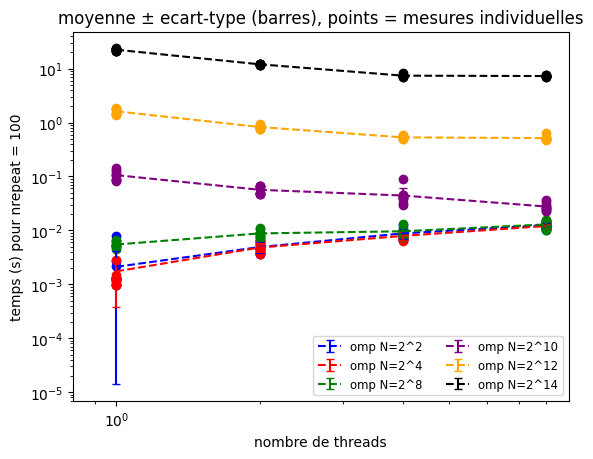

In [3]:
df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie2_vecteur')
versions_plot = ['omp']

for N in df['N'].unique():
    df_size = df[df['N'] == int(N)]

    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df_size[df_size['version'] == version]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).mean(numeric_only=True).reset_index()
        std_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).std(numeric_only=True).reset_index()

        plt.errorbar(mean_stats['nbcore'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                 linestyle=linestyle, color=color_num_steps[N], label=f"{version} N=2^{int(np.log2(N))}")
        plt.yscale('log')
        plt.xscale('log')
        plt.scatter(df_plot['nbcore'], df_plot['runtime'], color=color_num_steps[N])

plt.xlabel('nombre de threads')
plt.ylabel('temps (s) pour nrepeat = 100')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Strong Scaling

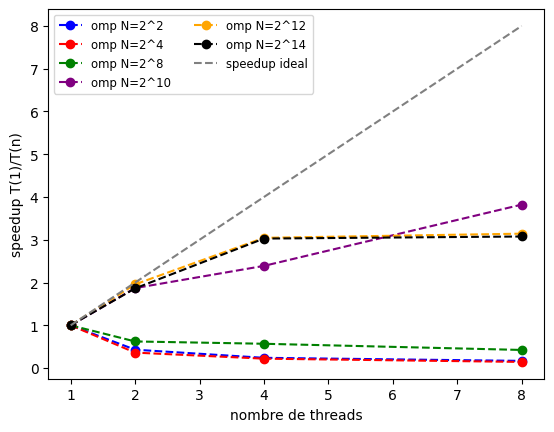

In [4]:
fig_speedup = plt.figure()

for N in df['N'].unique():
    df_size = df[df['N'] == int(N)]

    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df_size[df_size['version'] == version]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).mean(numeric_only=True).reset_index()
        mean_stats = mean_stats.sort_values('nbcore')
        if 1 not in mean_stats['nbcore'].values:
            continue

        t1 = mean_stats[mean_stats['nbcore'] == 1]['runtime'].values[0]
        speedup = t1 / mean_stats['runtime']

        plt.plot(mean_stats['nbcore'], speedup, linestyle=linestyle,
                 color=color_num_steps[N], marker='o', label=f"{version} N=2^{int(np.log2(N))}")

plt.plot([1, 2, 4, 8], [1, 2, 4, 8], linestyle='--', color='gray', label='speedup ideal')
plt.xlabel('nombre de threads')
plt.ylabel('speedup T(1)/T(n)')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Bande passante

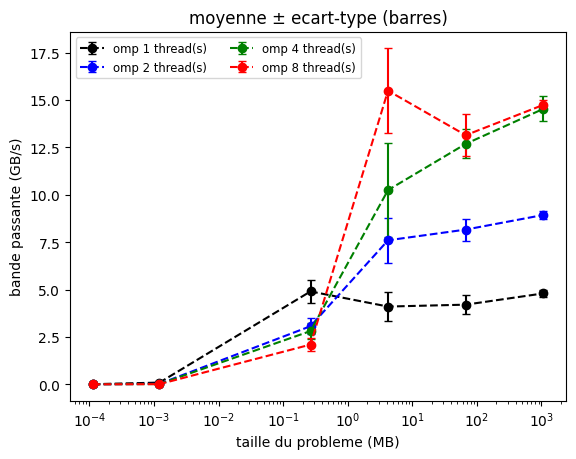

In [5]:
color_core = {1: "black", 2: "blue", 4: "green", 8: "red"}

for version, linestyle in version_linestyle.items():
    if version not in versions_plot:
        continue
    df_v = df[df['version'] == version]
    for ncore in sorted(df_v['nbcore'].unique()):
        df_plot = df_v[df_v['nbcore'] == ncore]
        mean_stats = df_plot.groupby(['N', 'M']).mean(numeric_only=True).reset_index().sort_values('size_mb')
        std_stats = df_plot.groupby(['N', 'M']).std(numeric_only=True).reset_index().set_index(['N', 'M']).loc[list(zip(mean_stats['N'], mean_stats['M']))]

        plt.errorbar(mean_stats['size_mb'], mean_stats['bandwidth'], yerr=std_stats['bandwidth'].values, capsize=3,
                     linestyle=linestyle, color=color_core[ncore], marker='o', label=f"{version} {ncore} thread(s)")

plt.xscale('log')
plt.xlabel('taille du probleme (MB)')
plt.ylabel('bande passante (GB/s)')
plt.title('moyenne ± ecart-type (barres)')
plt.legend(fontsize='small', ncol=2)
plt.show()

In [ ]:
# (_fmt, _taille, _label sont definies dans la cellule de la question 2.4)
def tableaux_omp(df):
    g = df.groupby(['version', 'nbcore', 'N']).agg(t=('runtime', 'mean'), s=('runtime', 'std'),
                                                   bw=('bandwidth', 'mean'), n=('runtime', 'count')).reset_index()
    cols = [('seq', 1, 'séquentiel'), ('omp', 1, '1 thread'), ('omp', 2, '2 threads'),
            ('omp', 4, '4 threads'), ('omp', 8, '8 threads')]
    get = lambda v, c, N: g[(g.version == v) & (g.nbcore == c) & (g.N == N)].iloc[0]
    hdr = "| N x M (taille de A) | " + " | ".join(c[2] for c in cols) + " |\n|---|" + "---|" * len(cols) + "\n"
    A, B, C = hdr, "| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |\n|---|---|---|---|---|\n", hdr
    for N in sorted(df['N'].unique()):
        lab = _label(df, N)
        ra, rb, rc = lab, lab, lab
        t1 = get('omp', 1, N).t
        for v, c, _ in cols:
            r = get(v, c, N)
            ra += f" {_fmt(r.t*1000)} ± {_fmt(r.s*1000)} |"
            rc += f" {_fmt(r.bw)} |"
            if v == 'omp':
                rb += f" {t1/r.t:.2f} |"
        A += ra + "\n"; B += rb + "\n"; C += rc + "\n"
    return A, B, C, int(g['n'].min())

A, B, C, n = tableaux_omp(df[df['version'].isin(['seq', 'omp'])])
display(Markdown(f"**Temps moyen ± écart-type (ms), pour nrepeat = 100, sur {n} exécutions par configuration**\n\n{A}\n"
                 f"**Speedup T(1)/T(n)** (T(1) = OpenMP a 1 thread)\n\n{B}\n"
                 f"**Bande passante moyenne (GB/s)**\n\n{C}"))

**Temps moyen ± écart-type (ms), pour nrepeat = 100, sur 10 exécutions par configuration**

| N x M (taille de A) | séquentiel | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.043 ± 0.016 | 2.11 ± 2.10 | 4.92 ± 1.09 | 8.80 ± 1.77 | 12.5 ± 1.43 |
| 2^4 x 2^3 (1216 o) | 0.057 ± 0.017 | 1.74 ± 1.36 | 4.82 ± 0.911 | 7.91 ± 1.25 | 12.1 ± 1.10 |
| 2^8 x 2^7 (265 Ko) | 4.93 ± 0.734 | 5.48 ± 0.662 | 8.80 ± 1.26 | 9.64 ± 1.53 | 12.9 ± 2.00 |
| 2^10 x 2^9 (4.21 Mo) | 101 ± 11.8 | 106 ± 20.8 | 56.6 ± 9.06 | 44.3 ± 16.2 | 27.7 ± 4.42 |
| 2^12 x 2^11 (67.2 Mo) | 1671 ± 165 | 1617 ± 189 | 826 ± 59.2 | 531 ± 32.5 | 514 ± 49.3 |
| 2^14 x 2^13 (1.07 Go) | 23315 ± 1334 | 22406 ± 880 | 12020 ± 294 | 7399 ± 353 | 7282 ± 137 |

**Speedup T(1)/T(n)** (T(1) = OpenMP a 1 thread)

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 1.00 | 0.43 | 0.24 | 0.17 |
| 2^4 x 2^3 (1216 o) | 1.00 | 0.36 | 0.22 | 0.14 |
| 2^8 x 2^7 (265 Ko) | 1.00 | 0.62 | 0.57 | 0.42 |
| 2^10 x 2^9 (4.21 Mo) | 1.00 | 1.87 | 2.39 | 3.82 |
| 2^12 x 2^11 (67.2 Mo) | 1.00 | 1.96 | 3.05 | 3.14 |
| 2^14 x 2^13 (1.07 Go) | 1.00 | 1.86 | 3.03 | 3.08 |

**Bande passante moyenne (GB/s)**

| N x M (taille de A) | séquentiel | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.301 | 0.008 | 0.002 | 0.001 | 0.001 |
| 2^4 x 2^3 (1216 o) | 2.28 | 0.092 | 0.026 | 0.016 | 0.010 |
| 2^8 x 2^7 (265 Ko) | 5.47 | 4.90 | 3.07 | 2.81 | 2.10 |
| 2^10 x 2^9 (4.21 Mo) | 4.21 | 4.11 | 7.60 | 10.3 | 15.5 |
| 2^12 x 2^11 (67.2 Mo) | 4.05 | 4.21 | 8.17 | 12.7 | 13.1 |
| 2^14 x 2^13 (1.07 Go) | 4.62 | 4.80 | 8.94 | 14.5 | 14.8 |


### Question 2.8 - Discussion (OpenMP)

Voici les mesures pour la version OpenMP (moyenne ± écart-type, comme demandé dans la méthodologie du sujet).

**Temps moyen ± écart-type (ms), pour nrepeat = 100, sur 10 exécutions par configuration**

| N x M (taille de A) | séquentiel | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.043 ± 0.016 | 2.11 ± 2.10 | 4.92 ± 1.09 | 8.80 ± 1.77 | 12.5 ± 1.43 |
| 2^4 x 2^3 (1216 o) | 0.057 ± 0.017 | 1.74 ± 1.36 | 4.82 ± 0.911 | 7.91 ± 1.25 | 12.1 ± 1.10 |
| 2^8 x 2^7 (265 Ko) | 4.93 ± 0.734 | 5.48 ± 0.662 | 8.80 ± 1.26 | 9.64 ± 1.53 | 12.9 ± 2.00 |
| 2^10 x 2^9 (4.21 Mo) | 101 ± 11.8 | 106 ± 20.8 | 56.6 ± 9.06 | 44.3 ± 16.2 | 27.7 ± 4.42 |
| 2^12 x 2^11 (67.2 Mo) | 1671 ± 165 | 1617 ± 189 | 826 ± 59.2 | 531 ± 32.5 | 514 ± 49.3 |
| 2^14 x 2^13 (1.07 Go) | 23315 ± 1334 | 22406 ± 880 | 12020 ± 294 | 7399 ± 353 | 7282 ± 137 |

**Speedup T(1)/T(n)** (T(1) = OpenMP à 1 thread)

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 1.00 | 0.43 | 0.24 | 0.17 |
| 2^4 x 2^3 (1216 o) | 1.00 | 0.36 | 0.22 | 0.14 |
| 2^8 x 2^7 (265 Ko) | 1.00 | 0.62 | 0.57 | 0.42 |
| 2^10 x 2^9 (4.21 Mo) | 1.00 | 1.87 | 2.39 | 3.82 |
| 2^12 x 2^11 (67.2 Mo) | 1.00 | 1.96 | 3.05 | 3.14 |
| 2^14 x 2^13 (1.07 Go) | 1.00 | 1.86 | 3.03 | 3.08 |

**Bande passante moyenne (GB/s)**

| N x M (taille de A) | séquentiel | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.301 | 0.008 | 0.002 | 0.001 | 0.001 |
| 2^4 x 2^3 (1216 o) | 2.28 | 0.092 | 0.026 | 0.016 | 0.010 |
| 2^8 x 2^7 (265 Ko) | 5.47 | 4.90 | 3.07 | 2.81 | 2.10 |
| 2^10 x 2^9 (4.21 Mo) | 4.21 | 4.11 | 7.60 | 10.3 | 15.5 |
| 2^12 x 2^11 (67.2 Mo) | 4.05 | 4.21 | 8.17 | 12.7 | 13.1 |
| 2^14 x 2^13 (1.07 Go) | 4.62 | 4.80 | 8.94 | 14.5 | 14.8 |

Pour les petites tailles (jusqu'à 265 Ko), OpenMP est plus lent que le séquentiel et empire avec le nombre de threads. À 2^2 x 2^1 le temps passe de 2.11 ms (1 thread, mesure très dispersée : ± 2.10 ms) à 12.5 ms (8 threads) alors que le séquentiel prend 0.043 ms : le travail utile est négligeable devant le coût de création et de synchronisation de l'équipe de threads. Cela se cumule à chaque répétition (100 fois), et ce coût augmente avec le nombre de threads. Même à 265 Ko, le speedup reste inférieur à 1.

À partir de 4.21 Mo, le parallélisme devient rentable, mais le speedup sature bien avant l'idéal. À 1.07 Go, on gagne un facteur 1.86 avec 2 threads (idéal : 2), 3.03 avec 4 et seulement 3.08 avec 8 (idéal : 8). Passer de 4 à 8 threads n'apporte presque rien aux grandes tailles (7399 ms -> 7282 ms à 1.07 Go).

Pour 67.2 Mo et plus, cette saturation pourrait s'expliquer par une limite de bande passante mémoire. La bande passante monte de 4.80 GB/s (1 thread) à environ 13-15 GB/s (13.1 GB/s à 67.2 Mo, 14.5 puis 14.8 GB/s à 4 puis 8 threads à 1.07 Go) et ne bouge plus entre 4 et 8 threads. Une fois ce plafond atteint (probablement celui de la mémoire de la machine), ajouter des cœurs ne fait pas arriver les données plus vite. Un seul cœur n'atteint que ~4.6-4.8 GB/s, soit environ un tiers du plafond, donc il faut environ 3 à 4 cœurs pour l'approcher (8.94 GB/s à 2 threads, 14.5 GB/s à 4 threads à 1.07 Go). Ce plafond n'explique cependant pas tout : aux tailles inférieures, la bande passante reste très en dessous (2.10 GB/s à 8 threads pour 265 Ko) : cela s'explique peut-être par un coût de synchronisation des threads qui domine sur la mémoire.

Le meilleur speedup est à 4.21 Mo avec 8 threads (3.82). Cette taille est trop grande pour le L2 d'un cœur mais tient dans le L3 de 12 Mo partagé. Par ailleurs pour cette mesure la bande passante (15.5 GB/s) est un peu supérieure à celle des tailles plus grandes (13.1 et 14.8 GB/s), avec un coût de synchronisation déjà amorti. Il est possible que le L3 y contribue. Elle reste cependant modeste pour une matrice qui tient dans le cache : le facteur limitant semble être le calcul scalaire (même à 1 thread, seulement 4.11 GB/s) et le coût de synchronisation des threads plutôt que la mémoire.

8 threads sur 6 cœurs physiques. Le processeur a 6 cœurs et 12 threads (hyperthreading). Le speedup de 8 threads ne peut donc pas dépasser environ 6, et les threads supplémentaires partagent les ressources d'un cœur. Et si on ajoute aussi la saturation mémoire, cela pourrait expliquer le gain quasi nul de 4 à 8 threads.

Remarque sur les mesures. À 4.21 Mo avec 4 threads, une exécution est nettement plus lente que les neuf autres (point isolé sur le graphe de temps), ce qui dégrade la moyenne (speedup 2.39 en dessous de la tendance). le bruit d'un autre processus de la machine possiblement.

### Question 2.9 - Ajout du pragma OpenMP SIMD

Ajout de `#pragma omp simd reduction(+:sum)` sur la boucle interne (sur `j`), **en conservant** `#pragma omp parallel for reduction(+:result)` sur la boucle externe. Le pragma autorise le compilateur à vectoriser le produit scalaire (plusieurs `double` par instruction). La clause `reduction(+:sum)` est nécessaire pour vectoriser car la somme de flottants n'est pas associative.

In [3]:
from pathlib import Path

Path("src/2_9_vector_simd.cpp").write_text(r"""/*
//@HEADER
// ************************************************************************
//
//                        Kokkos v. 2.0
//              Copyright (2014) Sandia Corporation
//
// Under the terms of Contract DE-AC04-94AL85000 with Sandia Corporation,
// the U.S. Government retains certain rights in this software.
//
// Redistribution and use in source and binary forms, with or without
// modification, are permitted provided that the following conditions are
// met:
//
// 1. Redistributions of source code must retain the above copyright
// notice, this list of conditions and the following disclaimer.
//
// 2. Redistributions in binary form must reproduce the above copyright
// notice, this list of conditions and the following disclaimer in the
// documentation and/or other materials provided with the distribution.
//
// 3. Neither the name of the Corporation nor the names of the
// contributors may be used to endorse or promote products derived from
// this software without specific prior written permission.
//
// THIS SOFTWARE IS PROVIDED BY SANDIA CORPORATION "AS IS" AND ANY
// EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
// IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR
// PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL SANDIA CORPORATION OR THE
// CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL,
// EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO,
// PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR
// PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF
// LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING
// NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS
// SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
//
// Questions Contact  H. Carter Edwards (hcedwar@sandia.gov)
//
// ************************************************************************
//@HEADER
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>

#include <cmath>
#include <omp.h>
#include <fstream>

void checkSizes( int &N, int &M, int &S, int &nrepeat );

int main( int argc, char* argv[] )
{
  int N = -1;         // number of rows 2^12
  int M = -1;         // number of columns 2^10
  int S = -1;         // total size 2^22
  int nrepeat = 100;  // number of repeats of the test
  int nbthreads = omp_get_max_threads(); // number of threads to use

  // Read command line arguments.
  for ( int i = 0; i < argc; i++ ) {
    if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-Rows" ) == 0 ) ) {
      N = pow( 2, atoi( argv[ ++i ] ) );
      printf( "  User N is %d\n", N );
    }
    else if ( ( strcmp( argv[ i ], "-M" ) == 0 ) || ( strcmp( argv[ i ], "-Columns" ) == 0 ) ) {
      M = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User M is %d\n", M );
    }
    else if ( ( strcmp( argv[ i ], "-S" ) == 0 ) || ( strcmp( argv[ i ], "-Size" ) == 0 ) ) {
      S = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User S is %d\n", S );
    }
    else if ( strcmp( argv[ i ], "-nrepeat" ) == 0 ) {
      nrepeat = atoi( argv[ ++i ] );
    }
    else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-nbthreads" ) == 0 ) ){
      nbthreads = atoi( argv[ ++i ] );
      omp_set_num_threads(nbthreads);
      printf( "  User nbthreads is %d\n", nbthreads );
    }
    else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
      printf( "  y^T*A*x Options:\n" );
      printf( "  -Rows (-N) <int>:      exponent num, determines number of rows 2^num (default: 2^12 = 4096)\n" );
      printf( "  -Columns (-M) <int>:   exponent num, determines number of columns 2^num (default: 2^10 = 1024)\n" );
      printf( "  -Size (-S) <int>:      exponent num, determines total matrix size 2^num (default: 2^22 = 4096*1024 )\n" );
      printf( "  -nrepeat <int>:        number of repetitions (default: 100)\n" );
      printf( "  -nbthreads (-C) <int>:      number of threads to use (default: max available)\n" );
      printf( "  -help (-h):            print this message\n\n" );
      exit( 1 );
    }
  }

  // Check sizes.
  checkSizes( N, M, S, nrepeat );

  omp_set_num_threads(nbthreads);

  // Allocate x,y,A
  auto y = (double*) std::malloc(N*sizeof(double));
  auto x = (double*) std::malloc(M*sizeof(double));
  auto A = (double*) std::malloc(N*M*sizeof(double));

  // Initialize y vector to 1.
  for (int i = 0; i < N; i++) {
    y[i] = 1.0;
  }

  // Initialize x vector to 1.
  for (int i = 0; i < M; i++) {
    x[i] = 1.0;
  }

  // Initialize A matrix, you can use a 1D index if you want a flat structure (i.e. a 1D array) e.g. j*M+i is the same than [j][i]
  for (int j = 0; j < N; j++) {
    for (int i = 0; i < M; i++) {
      A[j*M+i] = 1.0;
    }
  }

  // Timer products.
  struct timeval begin, end;

  gettimeofday( &begin, NULL );

  for ( int repeat = 0; repeat < nrepeat; repeat++ ) {
    // For each line i
        // Multiply the i lines with the vector x 
        // Sum the results of the previous step into a single variable
        double result = 0.0;
        #pragma omp parallel for reduction(+:result) // chaque thread garde une copie local de result et 
                                                     // openmp les additionne à la fin de la boucle à la fin
        for (int i = 0; i < N; i++) {
            double sum = 0.0;
            # pragma omp simd reduction(+:sum) // on vectorise la somme pour que le thread puisse traiter 
                                               // plusieurs éléments en même temps
            for (int j = 0; j < M; j++) {
                sum += A[i*M+j] * x[j];
            }
            // Multiply the result of the previous step with the i value of vector y
            // Sum the results of the previous step into a single variable (result)
            result += sum * y[i];
        }
        

    // Output result.
    if ( repeat == ( nrepeat - 1 ) ) {
      printf( "  Computed result for %d x %d is %lf\n", N, M, result );
    }

    const double solution = (double) N * (double) M;

    if ( result != solution ) {
      printf( "  Error: result( %lf ) != solution( %lf )\n", result, solution );
    }
  }

  gettimeofday( &end, NULL );

  // Calculate time.
  //double time = timer.seconds();
  double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );

  // Calculate bandwidth.
  // Each matrix A row (each of length M) is read once.
  // The x vector (of length M) is read N times.
  // The y vector (of length N) is read once.
  // double Gbytes = 1.0e-9 * double( sizeof(double) * ( 2 * M * N + N ) );
  double Gbytes = 1.0e-9 * double( sizeof(double) * ( M + M * N + N ) );

  // Print results (problem size, time and bandwidth in GB/s).
  printf( "  N( %d ) M( %d ) nrepeat ( %d ) problem( %g MB ) time( %g s ) bandwidth( %g GB/s )\n",
          N, M, nrepeat, Gbytes * 1000, time, Gbytes * nrepeat / time );
  std::ofstream("stats_part2.csv", std::ios::app) << "simd," << nbthreads << "," << N << "," << M << "," << Gbytes * 1000 << "," << time << "," << Gbytes * nrepeat / time << "\n";

  std::free(A);
  std::free(y);
  std::free(x);

  return 0;
}

void checkSizes( int &N, int &M, int &S, int &nrepeat ) {
  // If S is undefined and N or M is undefined, set S to 2^22 or the bigger of N and M.
  if ( S == -1 && ( N == -1 || M == -1 ) ) {
    S = pow( 2, 22 );
    if ( S < N ) S = N;
    if ( S < M ) S = M;
  }

  // If S is undefined and both N and M are defined, set S = N * M.
  if ( S == -1 ) S = N * M;

  // If both N and M are undefined, fix row length to the smaller of S and 2^10 = 1024.
  if ( N == -1 && M == -1 ) {
    if ( S > 1024 ) {
      M = 1024;
    }
    else {
      M = S;
    }
  }

  // If only M is undefined, set it.
  if ( M == -1 ) M = S / N;

  // If N is undefined, set it.
  if ( N == -1 ) N = S / M;

  printf( "  Total size S = %d N = %d M = %d\n", S, N, M );

  // Check sizes.
  if ( ( S < 0 ) || ( N < 0 ) || ( M < 0 ) || ( nrepeat < 0 ) ) {
    printf( "  Sizes must be greater than 0.\n" );
    exit( 1 );
  }

  if ( ( N * M ) != S ) {
    printf( "  N * M != S\n" );
    exit( 1 );
  }
}
""")

8251

In [4]:
!g++ -o bin/2_9_vector_simd src/2_9_vector_simd.cpp -fopenmp -O3 -march=native

In [5]:
!.\bin\2_9_vector_simd.exe -N 12 -M 10 -C 4

  User N is 4096
  User M is 1024
  User nbthreads is 4
  Total size S = 4194304 N = 4096 M = 1024
  Computed result for 4096 x 1024 is 4194304.000000
  N( 4096 ) M( 1024 ) nrepeat ( 100 ) problem( 33.5954 MB ) time( 0.249168 s ) bandwidth( 13.483 GB/s )


### Question 2.10 - Évaluation de performance (OpenMP + SIMD)

Même protocole qu'en 2.6.

In [6]:
nettoyer_csv("partie2_vecteur")

for (n_exp, m_exp) in pairs:
    for ncore in nb_core:
        for repeat in range(NB_REPETITIONS - deja_faites("partie2_vecteur", "simd", ncore, 2 ** n_exp)):
            args = ("./bin/2_9_vector_simd.exe", "-C", str(ncore), "-N", str(n_exp), "-M", str(m_exp))
            popen = subprocess.Popen(args, stdout=subprocess.PIPE)
            popen.wait()
        fusionner("partie2_vecteur")

### Question 2.11 - Figures de performance (OpenMP + SIMD)
#### Temps en fonction du nombre de threads

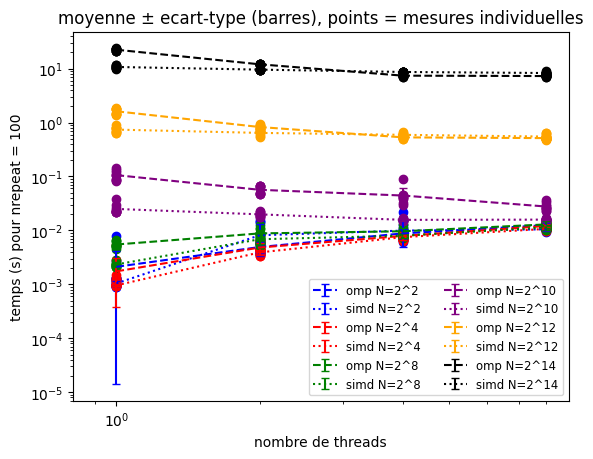

In [3]:
df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie2_vecteur')
versions_plot = ['omp', 'simd']

for N in df['N'].unique():
    df_size = df[df['N'] == int(N)]

    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df_size[df_size['version'] == version]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).mean(numeric_only=True).reset_index()
        std_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).std(numeric_only=True).reset_index()

        plt.errorbar(mean_stats['nbcore'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                 linestyle=linestyle, color=color_num_steps[N], label=f"{version} N=2^{int(np.log2(N))}")
        plt.yscale('log')
        plt.xscale('log')
        plt.scatter(df_plot['nbcore'], df_plot['runtime'], color=color_num_steps[N])

plt.xlabel('nombre de threads')
plt.ylabel('temps (s) pour nrepeat = 100')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Strong Scaling

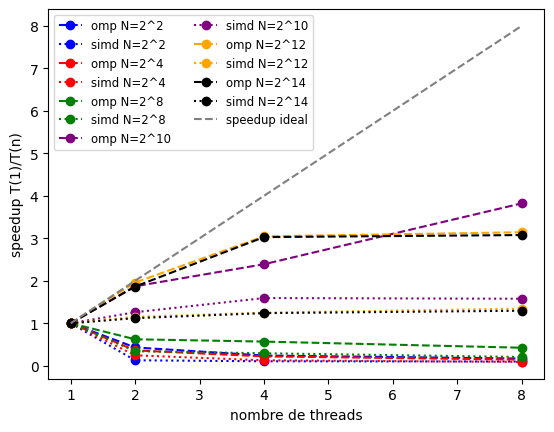

In [4]:
fig_speedup = plt.figure()

for N in df['N'].unique():
    df_size = df[df['N'] == int(N)]

    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df_size[df_size['version'] == version]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).mean(numeric_only=True).reset_index()
        mean_stats = mean_stats.sort_values('nbcore')
        if 1 not in mean_stats['nbcore'].values:
            continue

        t1 = mean_stats[mean_stats['nbcore'] == 1]['runtime'].values[0]
        speedup = t1 / mean_stats['runtime']

        plt.plot(mean_stats['nbcore'], speedup, linestyle=linestyle,
                 color=color_num_steps[N], marker='o', label=f"{version} N=2^{int(np.log2(N))}")

plt.plot([1, 2, 4, 8], [1, 2, 4, 8], linestyle='--', color='gray', label='speedup ideal')
plt.xlabel('nombre de threads')
plt.ylabel('speedup T(1)/T(n)')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Bande passante

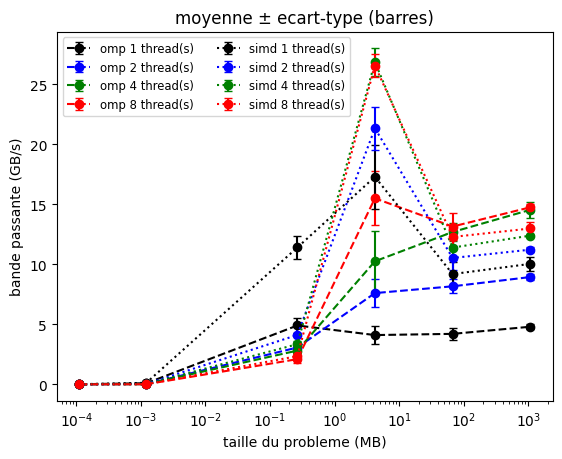

In [5]:
color_core = {1: "black", 2: "blue", 4: "green", 8: "red"}

for version, linestyle in version_linestyle.items():
    if version not in versions_plot:
        continue
    df_v = df[df['version'] == version]
    for ncore in sorted(df_v['nbcore'].unique()):
        df_plot = df_v[df_v['nbcore'] == ncore]
        mean_stats = df_plot.groupby(['N', 'M']).mean(numeric_only=True).reset_index().sort_values('size_mb')
        std_stats = df_plot.groupby(['N', 'M']).std(numeric_only=True).reset_index().set_index(['N', 'M']).loc[list(zip(mean_stats['N'], mean_stats['M']))]

        plt.errorbar(mean_stats['size_mb'], mean_stats['bandwidth'], yerr=std_stats['bandwidth'].values, capsize=3,
                     linestyle=linestyle, color=color_core[ncore], marker='o', label=f"{version} {ncore} thread(s)")

plt.xscale('log')
plt.xlabel('taille du probleme (MB)')
plt.ylabel('bande passante (GB/s)')
plt.title('moyenne ± ecart-type (barres)')
plt.legend(fontsize='small', ncol=2)
plt.show()

In [ ]:

def tableaux_simd(df):
    g = df.groupby(['version', 'nbcore', 'N']).agg(t=('runtime', 'mean'), s=('runtime', 'std'),
                                                   bw=('bandwidth', 'mean'), n=('runtime', 'count')).reset_index()
    get = lambda v, c, N: g[(g.version == v) & (g.nbcore == c) & (g.N == N)].iloc[0]
    thr = [1, 2, 4, 8]
    h4 = "| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |\n|---|---|---|---|---|\n"
    A, B, C, D = h4, h4, h4, h4
    for N in sorted(df['N'].unique()):
        lab = _label(df, N)
        ra, rb, rc, rd = lab, lab, lab, lab
        t1 = get('simd', 1, N).t
        for c in thr:
            s, o = get('simd', c, N), get('omp', c, N)
            ra += f" {_fmt(s.t*1000)} ± {_fmt(s.s*1000)} |"
            rb += f" {t1/s.t:.2f} |"
            rc += f" {_fmt(s.bw)} |"
            rd += f" {o.t/s.t:.2f} |"
        A += ra + "\n"; B += rb + "\n"; C += rc + "\n"; D += rd + "\n"
    return A, B, C, D, int(g[g.version == 'simd']['n'].min())

A, B, C, D, n = tableaux_simd(df)
display(Markdown(f"**OpenMP + SIMD : temps moyen ± écart-type (ms), nrepeat = 100, {n} exécutions par configuration**\n\n{A}\n"
                 f"**Speedup T(1)/T(n)** (T(1) = OpenMP + SIMD a 1 thread)\n\n{B}\n"
                 f"**Bande passante moyenne (GB/s)**\n\n{C}\n"
                 f"**Gain de SIMD = T(OpenMP) / T(OpenMP + SIMD)**\n\n{D}"))

**OpenMP + SIMD : temps moyen ± écart-type (ms), nrepeat = 100, 10 exécutions par configuration**

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 1.04 ± 0.125 | 8.13 ± 4.83 | 9.92 ± 5.05 | 10.5 ± 0.537 |
| 2^4 x 2^3 (1216 o) | 0.959 ± 0.036 | 3.91 ± 0.426 | 7.51 ± 0.838 | 10.7 ± 0.698 |
| 2^8 x 2^7 (265 Ko) | 2.34 ± 0.216 | 6.86 ± 2.19 | 7.98 ± 0.700 | 11.4 ± 1.00 |
| 2^10 x 2^9 (4.21 Mo) | 25.0 ± 4.95 | 19.8 ± 1.67 | 15.7 ± 0.672 | 15.9 ± 0.565 |
| 2^12 x 2^11 (67.2 Mo) | 740 ± 85.4 | 643 ± 58.2 | 592 ± 41.9 | 549 ± 41.3 |
| 2^14 x 2^13 (1.07 Go) | 10729 ± 600 | 9573 ± 179 | 8669 ± 102 | 8283 ± 348 |

**Speedup T(1)/T(n)** (T(1) = OpenMP + SIMD a 1 thread)

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 1.00 | 0.13 | 0.10 | 0.10 |
| 2^4 x 2^3 (1216 o) | 1.00 | 0.25 | 0.13 | 0.09 |
| 2^8 x 2^7 (265 Ko) | 1.00 | 0.34 | 0.29 | 0.21 |
| 2^10 x 2^9 (4.21 Mo) | 1.00 | 1.26 | 1.59 | 1.58 |
| 2^12 x 2^11 (67.2 Mo) | 1.00 | 1.15 | 1.25 | 1.35 |
| 2^14 x 2^13 (1.07 Go) | 1.00 | 1.12 | 1.24 | 1.30 |

**Bande passante moyenne (GB/s)**

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.011 | 0.002 | 0.001 | 0.001 |
| 2^4 x 2^3 (1216 o) | 0.127 | 0.031 | 0.016 | 0.011 |
| 2^8 x 2^7 (265 Ko) | 11.4 | 4.11 | 3.35 | 2.35 |
| 2^10 x 2^9 (4.21 Mo) | 17.3 | 21.3 | 26.9 | 26.6 |
| 2^12 x 2^11 (67.2 Mo) | 9.19 | 10.5 | 11.4 | 12.3 |
| 2^14 x 2^13 (1.07 Go) | 10.0 | 11.2 | 12.4 | 13.0 |

**Gain de SIMD = T(OpenMP) / T(OpenMP + SIMD)**

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 2.03 | 0.60 | 0.89 | 1.20 |
| 2^4 x 2^3 (1216 o) | 1.82 | 1.23 | 1.05 | 1.13 |
| 2^8 x 2^7 (265 Ko) | 2.34 | 1.28 | 1.21 | 1.14 |
| 2^10 x 2^9 (4.21 Mo) | 4.24 | 2.85 | 2.82 | 1.75 |
| 2^12 x 2^11 (67.2 Mo) | 2.19 | 1.29 | 0.90 | 0.94 |
| 2^14 x 2^13 (1.07 Go) | 2.09 | 1.26 | 0.85 | 0.88 |


### Question 2.12 - Discussion (OpenMP + SIMD)

**OpenMP + SIMD : temps moyen ± écart-type (ms), nrepeat = 100, 10 exécutions par configuration**

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 1.04 ± 0.125 | 8.13 ± 4.83 | 9.92 ± 5.05 | 10.5 ± 0.537 |
| 2^4 x 2^3 (1216 o) | 0.959 ± 0.036 | 3.91 ± 0.426 | 7.51 ± 0.838 | 10.7 ± 0.698 |
| 2^8 x 2^7 (265 Ko) | 2.34 ± 0.216 | 6.86 ± 2.19 | 7.98 ± 0.700 | 11.4 ± 1.00 |
| 2^10 x 2^9 (4.21 Mo) | 25.0 ± 4.95 | 19.8 ± 1.67 | 15.7 ± 0.672 | 15.9 ± 0.565 |
| 2^12 x 2^11 (67.2 Mo) | 740 ± 85.4 | 643 ± 58.2 | 592 ± 41.9 | 549 ± 41.3 |
| 2^14 x 2^13 (1.07 Go) | 10729 ± 600 | 9573 ± 179 | 8669 ± 102 | 8283 ± 348 |

**Speedup T(1)/T(n)** (T(1) = OpenMP + SIMD à 1 thread)

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 1.00 | 0.13 | 0.10 | 0.10 |
| 2^4 x 2^3 (1216 o) | 1.00 | 0.25 | 0.13 | 0.09 |
| 2^8 x 2^7 (265 Ko) | 1.00 | 0.34 | 0.29 | 0.21 |
| 2^10 x 2^9 (4.21 Mo) | 1.00 | 1.26 | 1.59 | 1.58 |
| 2^12 x 2^11 (67.2 Mo) | 1.00 | 1.15 | 1.25 | 1.35 |
| 2^14 x 2^13 (1.07 Go) | 1.00 | 1.12 | 1.24 | 1.30 |

**Bande passante moyenne (GB/s)**

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.011 | 0.002 | 0.001 | 0.001 |
| 2^4 x 2^3 (1216 o) | 0.127 | 0.031 | 0.016 | 0.011 |
| 2^8 x 2^7 (265 Ko) | 11.4 | 4.11 | 3.35 | 2.35 |
| 2^10 x 2^9 (4.21 Mo) | 17.3 | 21.3 | 26.9 | 26.6 |
| 2^12 x 2^11 (67.2 Mo) | 9.19 | 10.5 | 11.4 | 12.3 |
| 2^14 x 2^13 (1.07 Go) | 10.0 | 11.2 | 12.4 | 13.0 |

**Gain de SIMD = T(OpenMP) / T(OpenMP + SIMD)**

| N x M (taille de A) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 2.03 | 0.60 | 0.89 | 1.20 |
| 2^4 x 2^3 (1216 o) | 1.82 | 1.23 | 1.05 | 1.13 |
| 2^8 x 2^7 (265 Ko) | 2.34 | 1.28 | 1.21 | 1.14 |
| 2^10 x 2^9 (4.21 Mo) | 4.24 | 2.85 | 2.82 | 1.75 |
| 2^12 x 2^11 (67.2 Mo) | 2.19 | 1.29 | 0.90 | 0.94 |
| 2^14 x 2^13 (1.07 Go) | 2.09 | 1.26 | 0.85 | 0.88 |

SIMD accélère nettement le calcul à 1 thread. Le gain est d'environ 2 à presque toutes les tailles (de 1.82 à 2.34), et monte à 4.24 à 4.21 Mo. Une explication possible : dans la boucle séquentielle, chaque addition `sum += ...` dépend de la précédente, et le compilateur n'a pas le droit de réordonner des additions flottantes, alors que la clause `reduction(+:sum)` autorise plusieurs sommes partielles en parallèle dans les registres vectoriels. À 1.07 Go, avec 1 seul thread, la bande passante est multipliée par 2 grâce à SIMD (10.0 GB/s contre 4.80 GB/s avec OpenMP seul).

Le gain de SIMD diminue quand le nombre de threads augmente, et disparaît en grande taille. À 67.2 Mo et 1.07 Go, le gain tombe de 2.19 et 2.09 (1 thread) à 1.29 et 1.26 (2 threads) puis passe sous 1 à 4 et 8 threads (0.90 et 0.94 à 67.2 Mo, 0.85 et 0.88 à 1.07 Go) : la version SIMD est légèrement plus lente que OpenMP seul. À 67.2 Mo et 1.07 Go, les deux versions se heurtent au même plafond de bande passante mémoire (~12-15 GB/s) : vectoriser ne fait pas arriver les données plus vite. À 1.07 Go, SIMD reste même 14 à 17 % plus lent que OpenMP seul à 4 et 8 threads, un écart supérieur à la variabilité des mesures. Je ne l'explique pas. Cela nuance l'hypothèse de la 2.8 : le plafond d'environ 15 GB/s n'est pas une limite absolue de la machine. Il apparaît pour les matrices qui ne tiennent pas dans le cache (67.2 Mo et plus), avec OpenMP seul comme avec SIMD. À 4.21 Mo, où la matrice tient dans le L3, SIMD le dépasse largement (voir plus bas).

Avec SIMD, le speedup en nombre de threads est moins bon qu'avec OpenMP seul (1.30 à 1.58 à 8 threads aux grandes tailles, contre 3.08 à 3.82). Ce n'est pas que SIMD parallélise moins bien : le temps à 1 thread est déjà bien meilleur, donc il reste moins à gagner avant de toucher le plafond mémoire. À 1.07 Go la version SIMD à 4 threads (8669 ms) n'est pas meilleure que OpenMP seul (7399 ms).

Le meilleur résultat absolu est à 4.21 Mo : jusqu'à 26.9 GB/s (SIMD, 4 threads). Cette valeur dépasse le plafond de ~15 GB/s, ce qui laisse penser que les données sont servies depuis le cache L3 (12 Mo) et non depuis la RAM. La matrice est pourtant la même avec OpenMP seul, qui n'atteint que 15.5 GB/s : une explication possible est que SIMD lève la limite du calcul scalaire, ce qui laisse apparaître la vitesse du cache, alors qu'OpenMP seul reste limité par le calcul et par le coût de synchronisation des threads. Au-delà du L3 (67.2 Mo), on semble retomber sur le plafond de la RAM.

Petites tailles (265 Ko et moins). Le coût de synchronisation des threads domine toujours (OpenMP et SIMD ont des temps proches, tous deux plus lents que le séquentiel à plusieurs threads), et le gain de SIMD y est modeste (1.14 à 1.28 à 265 Ko, mais aux deux plus petites tailles les mesures sont trop bruitées pour conclure : gain entre 0.60 et 1.23).

Pour conclure, concernant ce produit matrice-vecteur SIMD est la meilleure optimisation à 1 thread, et OpenMP la meilleure pour utiliser la mémoire en grande taille. Combiner les deux n'apporte plus rien dès que la mémoire est saturée. Le facteur limitant final semble être la bande passante mémoire, pas le calcul.

## 3. Fibonacci and linked list

### Question 3.1 - Ajout des pragmas OpenMP

Une boucle `while (p != NULL)` sur une liste chaînée n'est pas parallélisable avec `parallel for` (nombre d'itérations inconnu, pas d'accès direct au nœud k). Il faut donc utiliser des **tâches OpenMP** :
- `#pragma omp parallel` crée l'équipe de threads.
- `#pragma omp single` : un seul thread parcourt la liste et crée les tâches (sinon chaque nœud serait traité par chaque thread).
- `#pragma omp task firstprivate(p)` : un appel `processwork(p)` devient une tâche exécutable par n'importe quel thread libre. `firstprivate(p)` est nécessaire pour copier la valeur de `p` à la création de la tâche, alors que le thread créateur avance déjà (`p = p->next`).
- la barrière implicite de la fin de la région `parallel` attend la fin de toutes les tâches avant l'arrêt du chronomètre.

In [ ]:
from pathlib import Path

Path("src/3_1_fib.cpp").write_text(r"""/*
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <omp.h>
#include <fstream>

static int N = 5;

#ifndef FS
#define FS 38
#endif

struct node {
   int data;
   int fibdata;
   struct node* next;
};

int fib(int n) {
   int x, y;
   if (n < 2) {
      return (n);
   } else {
      x = fib(n - 1);
      y = fib(n - 2);
	  return (x + y);
   }
}

void processwork(struct node* p) 
{
   int n;
   n = p->data;
   p->fibdata = fib(n);
}

struct node* init_list(struct node* p) {
    int i;
    struct node* head = NULL;
    struct node* temp = NULL;
    
    head = (struct node*)malloc(sizeof(struct node));
    p = head;
    p->data = FS;
    p->fibdata = 0;
    for (i=0; i< N; i++) {
       temp  =  (struct node*)malloc(sizeof(struct node));
       p->next = temp;
       p = temp;
       p->data = FS + i + 1;
       p->fibdata = i+1;
    }
    p->next = NULL;
    return head;
}

int main(int argc, char *argv[]) {
      int nb_threads = omp_get_max_threads();

      // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_node" ) == 0 ) ) {
            N = atoi( argv[ ++i ] );
            printf( "  User num_node is %d\n", N );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-nbthreads" ) == 0 ) ){
            nb_threads = atoi( argv[ ++i ] );
            omp_set_num_threads(nb_threads);
            printf( "  User nbthreads is %d\n", nb_threads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Fib Options:\n" );
            printf( "  -num_node (-N) <int>:      Number of node computing fibonnaci numbers (by default 5)\n" );
            printf( "  -nbthreads (-C) <int>:      Number of threads to use (default: max available)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }
    
     struct node *p=NULL;
     struct node *temp=NULL;
     struct node *head=NULL;
     
	 printf("Process linked list\n");
     printf("  Each linked list node will be processed by function 'processwork()'\n");
     printf("  Each ll node will compute %d fibonacci numbers beginning with %d\n",N,FS);      
 
     p = init_list(p);
     head = p;
     omp_set_num_threads( nb_threads );

      // Timer products.
      struct timeval begin, end;

      gettimeofday( &begin, NULL );

      #pragma omp parallel
      {
         #pragma omp single
         {
            while (p != NULL) {
                #pragma omp task firstprivate(p)
                processwork(p);
                p = p->next;
            }
         }
      }

      gettimeofday( &end, NULL );

      // Calculate time.
      double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );
                
     p = head;
	 while (p != NULL) {
        printf("%d : %d\n",p->data, p->fibdata);
        temp = p->next;
        free (p);
        p = temp;
     }  
	 free (p);

     printf("Compute Time: %f seconds\n", time);
     std::ofstream("stats_part3.csv", std::ios::app) << "fib," << nb_threads << "," << N << "," << time << "\n";

     return 0;
}

""")

In [ ]:
!g++ -o bin/3_1_fib src/3_1_fib.cpp -fopenmp -O3 -march=native

In [ ]:
!.\bin\3_1_fib.exe -N 3 -C 4

### Question 3.2 - Évaluation de performance

L'énoncé demande N et M de 1000 à 18000, mais le programme n'a pas de paramètre M, et avec 1000 nœuds il faudrait calculer `fib(1038)`, ce qui serait beaucoup trop long. Le choix a donc été fait de faire varier N de 2 à 10 (soit 3 à 11 nœuds).

| N (nœuds - 1) | nb_core | répétitions |
|---|---|---|
| 2, 4, 6, 8, 10 | 1, 2, 4, 8 | 10 |

Le temps à 1 thread sert de référence séquentielle, et le coût total est dominé par le dernier nœud (`fib(38 + N)`), de l'ordre de 33 s pour N = 10 à 1 thread.

In [ ]:
nettoyer_csv("partie3_fib")

num_nodes = [2, 4, 6, 8, 10]
nb_core = [1, 2, 4, 8]

for nnodes in num_nodes:
    for ncore in nb_core:
        for repeat in range(NB_REPETITIONS - deja_faites("partie3_fib", "fib", ncore, nnodes)):
            args = ("./bin/3_1_fib.exe", "-C", str(ncore), "-N", str(nnodes))
            popen = subprocess.Popen(args, stdout=subprocess.PIPE)
            popen.wait()
        fusionner("partie3_fib")

### Question 3.3 - Figures de performance
#### Temps en fonction du nombre de threads

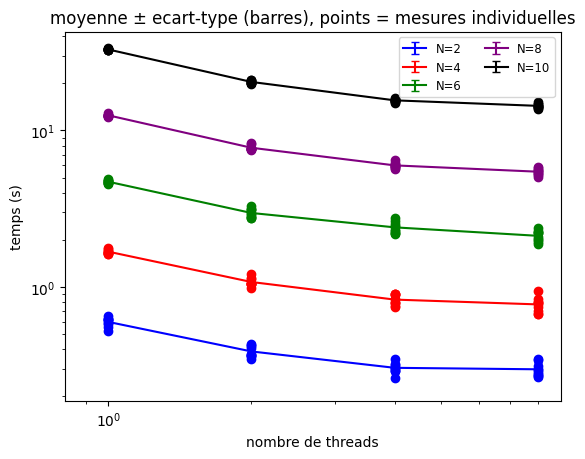

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie3_fib')

color_num_steps = {2 : "blue", 4 : "red", 6 : "green", 8 : "purple", 10 : "black"}
version_linestyle = {"fib" : "solid"}

for N in df['N'].unique():
    df_size = df[df['N'] == int(N)]

    for version, linestyle in version_linestyle.items():
        df_plot = df_size[df_size['version'] == version]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['N','version','nbcore']).mean().reset_index()
        std_stats = df_plot.groupby(['N','version','nbcore']).std().reset_index()

        plt.errorbar(mean_stats['nbcore'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                 linestyle=linestyle, color=color_num_steps[N], label=f"N={N}")
        plt.yscale('log')
        plt.xscale('log')
        plt.scatter(df_plot['nbcore'], df_plot['runtime'], color=color_num_steps[N])

plt.xlabel('nombre de threads')
plt.ylabel('temps (s)')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Strong Scaling

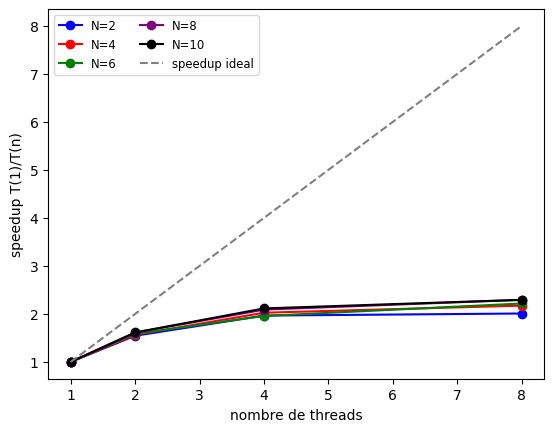

In [ ]:
fig_speedup = plt.figure()

for N in df['N'].unique():
    df_size = df[df['N'] == int(N)]

    for version, linestyle in version_linestyle.items():
        df_plot = df_size[df_size['version'] == version]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['N','version','nbcore']).mean().reset_index()
        mean_stats = mean_stats.sort_values('nbcore')
        if 1 not in mean_stats['nbcore'].values:
            continue

        t1 = mean_stats[mean_stats['nbcore'] == 1]['runtime'].values[0]
        speedup = t1 / mean_stats['runtime']

        plt.plot(mean_stats['nbcore'], speedup, linestyle=linestyle,
                 color=color_num_steps[N], marker='o', label=f"N={N}")

plt.plot([1,2,4,8], [1,2,4,8], linestyle='--', color='gray', label='speedup ideal')
plt.xlabel('nombre de threads')
plt.ylabel('speedup T(1)/T(n)')
plt.legend(fontsize='small', ncol=2)
plt.show()

In [ ]:
from IPython.display import Markdown, display

def fib_exact(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

def tableaux_fib(df):
    g = df.groupby(['N', 'nbcore']).runtime.agg(['mean', 'std', 'count']).reset_index()
    thr = [1, 2, 4, 8]
    A = "| N (noeuds - 1) | " + " | ".join(f"{c} thread" + ("s" if c > 1 else "") for c in thr) + " |\n|---|---|---|---|---|\n"
    B = "| N (noeuds - 1) | 2 threads | 4 threads | 8 threads | borne théorique (travail total / plus grosse tâche) |\n|---|---|---|---|---|\n"
    for N in sorted(df['N'].unique()):
        r = {c: g[(g.N == N) & (g.nbcore == c)].iloc[0] for c in thr}
        A += f"| {N} |" + "".join(f" {r[c]['mean']:.3g} ± {r[c]['std']:.2g} |" for c in thr) + "\n"
        taches = [fib_exact(38 + i) for i in range(N + 1)]
        B += f"| {N} |" + "".join(f" {r[1]['mean'] / r[c]['mean']:.2f} |" for c in thr[1:]) + f" {sum(taches) / max(taches):.2f} |\n"
    return A, B, int(g['count'].min())

A, B, n = tableaux_fib(df)
display(Markdown(f"**Fibonacci : temps moyen ± écart-type (s), {n} exécutions par configuration**\n\n{A}\n"
                 f"**Speedup T(1)/T(n)** et borne théorique du speedup\n\n{B}"))

**Fibonacci : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N (noeuds - 1) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2 | 0.598 ± 0.038 | 0.387 ± 0.031 | 0.304 ± 0.022 | 0.298 ± 0.029 |
| 4 | 1.68 ± 0.051 | 1.08 ± 0.064 | 0.83 ± 0.064 | 0.774 ± 0.083 |
| 6 | 4.7 ± 0.1 | 2.97 ± 0.19 | 2.4 ± 0.2 | 2.12 ± 0.16 |
| 8 | 12.5 ± 0.21 | 7.75 ± 0.28 | 5.98 ± 0.25 | 5.45 ± 0.26 |
| 10 | 32.9 ± 0.33 | 20.4 ± 0.4 | 15.6 ± 0.31 | 14.4 ± 0.45 |

**Speedup T(1)/T(n)** et borne théorique du speedup

| N (noeuds - 1) | 2 threads | 4 threads | 8 threads | borne théorique (travail total / plus grosse tâche) |
|---|---|---|---|---|
| 2 | 1.54 | 1.97 | 2.01 | 2.00 |
| 4 | 1.56 | 2.02 | 2.17 | 2.38 |
| 6 | 1.58 | 1.96 | 2.22 | 2.53 |
| 8 | 1.61 | 2.09 | 2.29 | 2.58 |
| 10 | 1.61 | 2.11 | 2.29 | 2.60 |


### Question 3.4 - Discussion

Voici les mesures pour Fibonacci (moyenne ± écart-type).

**Fibonacci : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N (nœuds - 1) | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 2 | 0.598 ± 0.038 | 0.387 ± 0.031 | 0.304 ± 0.022 | 0.298 ± 0.029 |
| 4 | 1.68 ± 0.051 | 1.08 ± 0.064 | 0.83 ± 0.064 | 0.774 ± 0.083 |
| 6 | 4.7 ± 0.1 | 2.97 ± 0.19 | 2.4 ± 0.2 | 2.12 ± 0.16 |
| 8 | 12.5 ± 0.21 | 7.75 ± 0.28 | 5.98 ± 0.25 | 5.45 ± 0.26 |
| 10 | 32.9 ± 0.33 | 20.4 ± 0.4 | 15.6 ± 0.31 | 14.4 ± 0.45 |

**Speedup T(1)/T(n)** et borne théorique du speedup

| N (nœuds - 1) | 2 threads | 4 threads | 8 threads | borne théorique (travail total / plus grosse tâche) |
|---|---|---|---|---|
| 2 | 1.54 | 1.97 | 2.01 | 2.00 |
| 4 | 1.56 | 2.02 | 2.17 | 2.38 |
| 6 | 1.58 | 1.96 | 2.22 | 2.53 |
| 8 | 1.61 | 2.09 | 2.29 | 2.58 |
| 10 | 1.61 | 2.11 | 2.29 | 2.60 |

Le speedup plafonne vers 2.3, bien loin des 8 threads. À N = 10, le temps passe de 32.9 s à 1 thread à 14.4 s à 8 threads, soit un speedup de 2.29 (l'efficacité tombe à environ 29 %). De 4 à 8 threads on gagne peu, entre 7 et 12 % selon N.

Je pense que la cause est le déséquilibre des tâches, pas OpenMP. Le nœud `i` calcule `fib(38 + i)` avec l'algorithme récursif naïf, donc son coût est multiplié par environ 1.6 à chaque nœud. Le dernier nœud est de loin le plus gros (environ 38 % du travail total à N = 10), et comme une tâche s'exécute sur un seul thread, le temps ne peut pas descendre sous la durée de cette tâche. Le speedup maximal vaut donc (travail total) / (plus grosse tâche), soit 2.00 pour N = 2 et 2.60 pour N = 10 (colonne « borne théorique »).

Mes mesures sont proches de cette borne : à 8 threads, elles en atteignent entre 88 et 100 % selon N. À N = 10 le temps minimal serait d'environ 12.6 s (32.9 s / 2.60) contre 14.4 s mesurés. Ce calcul suppose que le temps d'une tâche est proportionnel à la valeur de `fib`.

À 2 threads on est en dessous de 2 (1.54 à 1.61). Il me semble que cela vient de l'ordre de création des tâches : la liste va du plus petit au plus gros nœud, donc la plus grosse tâche démarre en dernier, sur un thread qui a déjà traité d'autres tâches. Une petite simulation de l'ordonnancement (durée proportionnelle à `fib`, chaque tâche confiée au premier thread libre) donne 1.61 pour N = 10, comme la mesure.

Si N augmentait, la borne se stabiliserait vers 2.6 : chaque nœud coûte 1.6 fois le précédent, donc le dernier pèse toujours environ 38 %. De 4 à 8 threads on gagnerait donc au plus une quinzaine de pourcents. À 4 et 8 threads mes mesures restent 5 à 10 % sous la simulation, sans doute à cause des 6 cœurs physiques partagés par 8 threads et du surcoût d'OpenMP.

Pour mieux exploiter les 8 threads, il faudrait découper la plus grosse tâche, par exemple en parallélisant `fib` lui-même avec des tâches récursives, ou au moins créer d'abord les plus grosses tâches.

Les écarts-types sont faibles (environ 1 % à N = 10), donc les conclusions ne reposent pas sur du bruit.

En résumé, la parallélisation par tâches fonctionne et approche la limite théorique, mais cette limite est basse (environ 2.6) à cause d'un seul nœud très coûteux.

## 4. Matrix multiplication and floating point précision

### Question 4.1 - Ajout du pragma OpenMP

Le produit C = A x B se calcule avec trois boucles imbriquées (`i` sur les lignes de A, `j` sur les colonnes de B, `k` pour la somme). Chaque ligne `i` de C est calculée indépendamment des autres, donc on parallélise la boucle externe avec `#pragma omp parallel for`.
- `j`, `k` et `tmp` doivent être privés à chaque thread (il suffit de les déclarer dans les boucles, OpenMP les rend automatiquement privés.
- Il n'y a pas besoin de `reduction`, car chaque thread écrit dans des cases différentes de C.

In [ ]:
from pathlib import Path

Path("src/4_1_matrix_mul_omp.cpp").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <omp.h>
#include <fstream>


#define AVAL 3.14
#define BVAL 5.42
#define TOL  0.001

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
	int nbthreads = omp_get_max_threads();       // nombre de threads
	int i,j,k;
	double *A, *B, *C, cval, tmp, err, errsq;
    double dN, dM, dP, mflops;


    
    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-nbthreads" ) == 0 ) ) {
            nbthreads = atoi( argv[ ++i ] );
            omp_set_num_threads( nbthreads );
            printf( "  User nbthreads is %d\n", nbthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -C <int>:              Number of threads (default: max available)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }
      
	
      A = (double *)malloc(Ndim*Pdim*sizeof(double));
      B = (double *)malloc(Pdim*Mdim*sizeof(double));
      C = (double *)malloc(Ndim*Mdim*sizeof(double));

	/* Initialize matrices */

	for (i=0; i<Ndim; i++)
		for (j=0; j<Pdim; j++)
			*(A+(i*Ndim+j)) = AVAL;

	for (i=0; i<Pdim; i++)
		for (j=0; j<Mdim; j++)
			*(B+(i*Pdim+j)) = BVAL;

	for (i=0; i<Ndim; i++)
		for (j=0; j<Mdim; j++)
			*(C+(i*Ndim+j)) = 0.0;

	/* Do the matrix product */
    
    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );
    
    #pragma omp parallel for
    for (int i=0; i<Ndim; i++){
		for (int j=0; j<Mdim; j++){
			double tmp = 0.0;
			for(int k=0;k<Pdim;k++){
				/* C(i,j) = sum(over k) A(i,k) * B(k,j) */
				tmp += *(A+(i*Ndim+k)) *  *(B+(k*Pdim+j));
			}
			*(C+(i*Ndim+j)) = tmp;
		}
	}
	/* Check the answer */


    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );
                
	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 2.0 * dN * dN * dN/(1000000.0* time);
 
	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_part4.csv", std::ios::app) << "omp," << nbthreads << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = Pdim * AVAL * BVAL;
	errsq = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = *(C+i*Ndim+j) - cval;
		    errsq += err * err;
		}
	}

	if (errsq > TOL) 
		printf("\n Errors in multiplication: %f",errsq);
	else
		printf("\n Hey, it worked");

	printf("\n all done \n");
}
""")

In [ ]:
!g++ -o bin/4_1_matrix_mul_omp src/4_1_matrix_mul_omp.cpp -fopenmp -O3 -march=native

In [ ]:
!.\bin\4_1_matrix_mul_omp.exe -C 4 -N 300 -M 300 -P 300

### Question 4.2 - Évaluation de performance

L'énoncé demande N et M de 1000 à 18000. Les matrices sont carrées, donc je donne la même valeur à N, M et P. Le produit coûte N^3 opérations, et le temps croît même plus vite : à 1 thread, N = 1000 prend environ 3 s et N = 2000 environ 69 s en `double` (environ 200 s en `half`). N = 4000 prendrait donc de l'ordre de dizaines de minutes par exécution, et la grille complète (jusqu'à 18000) est trop coûteuse avec 10 répétitions. Le choix a été fait de travailler avec N = M = P parmi 500, 1000 et 2000.

| N = M = P | nb_core | répétitions |
|---|---|---|
| 500, 1000, 2000 | 1, 2, 4, 8 | 10 |

In [ ]:
nettoyer_csv("partie4_matrices")

sizes = [500, 1000, 2000]
nb_core = [1, 2, 4, 8]

for n in sizes:
    for ncore in nb_core:
        for repeat in range(NB_REPETITIONS - deja_faites("partie4_matrices", "omp", ncore, n)):
            args = ("./bin/4_1_matrix_mul_omp.exe", "-C", str(ncore), "-N", str(n), "-M", str(n), "-P", str(n))
            popen = subprocess.Popen(args, stdout=subprocess.PIPE)
            popen.wait()
        fusionner("partie4_matrices")

### Question 4.3 - Figures de performance

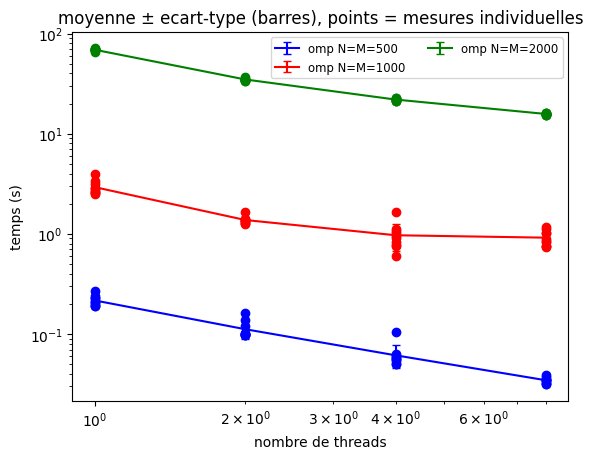

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

color_size = {500: "blue", 1000: "red", 2000: "green"}
version_linestyle = {"omp": "solid", "float": "dashed", "half": "dotted"}

df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie4_matrices')
# on ignore les executions de test (N, M, P differents) ecrites dans le meme fichier
df = df[df['N'].isin(color_size.keys()) & (df['N'] == df['M']) & (df['N'] == df['P'])]
versions_plot = ['omp']

for N in sorted(df['N'].unique()):
    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df[(df['N'] == N) & (df['version'] == version)]
        if df_plot.empty:
            continue

        keys = ['N', 'M', 'version', 'nbcore']
        mean_stats = df_plot.groupby(keys).mean(numeric_only=True).reset_index()
        std_stats = df_plot.groupby(keys).std(numeric_only=True).reset_index()

        plt.errorbar(mean_stats['nbcore'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                     linestyle=linestyle, color=color_size[N], label=f"{version} N=M={N}")
        plt.scatter(df_plot['nbcore'], df_plot['runtime'], color=color_size[N])

plt.yscale('log')
plt.xscale('log')
plt.xlabel('nombre de threads')
plt.ylabel('temps (s)')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Strong Scaling

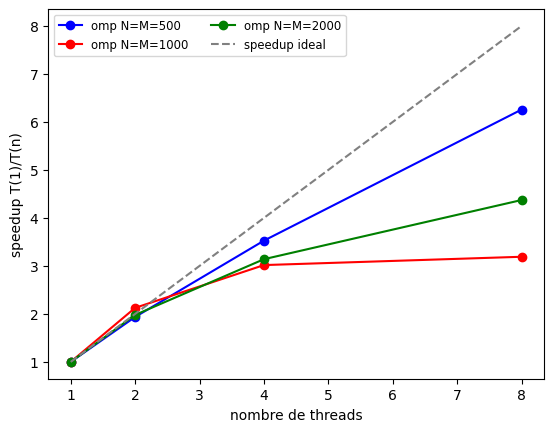

In [ ]:
fig_speedup = plt.figure()

for N in sorted(df['N'].unique()):
    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df[(df['N'] == N) & (df['version'] == version)]
        mean_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).mean(numeric_only=True).reset_index().sort_values('nbcore')
        if 1 not in mean_stats['nbcore'].values:
            continue

        t1 = mean_stats[mean_stats['nbcore'] == 1]['runtime'].values[0]
        speedup = t1 / mean_stats['runtime']

        plt.plot(mean_stats['nbcore'], speedup, linestyle=linestyle, color=color_size[N],
                 marker='o', label=f"{version} N=M={N}")

plt.plot([1, 2, 4, 8], [1, 2, 4, 8], linestyle='--', color='gray', label='speedup ideal')
plt.xlabel('nombre de threads')
plt.ylabel('speedup T(1)/T(n)')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Performance en mflops

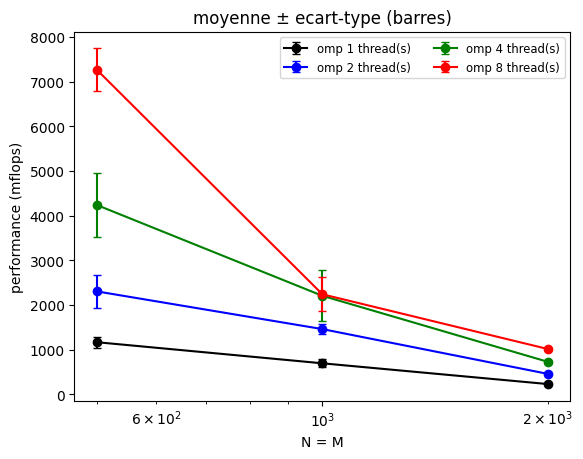

In [ ]:
color_core = {1: "black", 2: "blue", 4: "green", 8: "red"}

for version, linestyle in version_linestyle.items():
    if version not in versions_plot:
        continue
    df_v = df[df['version'] == version]
    for ncore in sorted(df_v['nbcore'].unique()):
        df_plot = df_v[df_v['nbcore'] == ncore]
        mean_stats = df_plot.groupby(['N', 'M']).mean(numeric_only=True).reset_index().sort_values('N')
        std_stats = df_plot.groupby(['N', 'M']).std(numeric_only=True).reset_index().sort_values('N')

        plt.errorbar(mean_stats['N'], mean_stats['mflops'], yerr=std_stats['mflops'], capsize=3,
                     linestyle=linestyle, color=color_core[ncore], marker='o', label=f"{version} {ncore} thread(s)")

plt.xscale('log')
plt.xlabel('N = M')
plt.ylabel('performance (mflops)')
plt.title('moyenne ± ecart-type (barres)')
plt.legend(fontsize='small', ncol=2)
plt.show()

In [ ]:
def tableaux_part4(df, version):
    d = df[(df['version'] == version) & (df['N'] == df['M']) & (df['N'] == df['P'])]
    g = d.groupby(['N', 'nbcore']).agg(t=('runtime', 'mean'), s=('runtime', 'std'),
                                       mf=('mflops', 'mean'), n=('runtime', 'count')).reset_index()
    thr = [1, 2, 4, 8]
    h = "| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |\n|---|---|---|---|---|\n"
    A, B, M = h, h, h
    for N in sorted(g['N'].unique()):
        r = g[g.N == N].set_index('nbcore')
        A += f"| {N} |" + "".join(f" {_fmt(r.t[c])} ± {_fmt(r.s[c])} |" for c in thr) + "\n"
        B += f"| {N} |" + "".join(f" {r.t[1] / r.t[c]:.2f} |" for c in thr) + "\n"
        M += f"| {N} |" + "".join(f" {r.mf[c]:.0f} |" for c in thr) + "\n"
    return A, B, M, int(g['n'].min())

df4 = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie4_matrices')
A, B, M, n = tableaux_part4(df4, 'omp')
display(Markdown(f"**double : temps moyen ± écart-type (s), {n} exécutions par configuration**\n\n{A}\n"
                 f"**Speedup T(1)/T(n)**\n\n{B}\n"
                 f"**Performance moyenne (mflops)**\n\n{M}"))

**double : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 0.216 ± 0.025 | 0.112 ± 0.023 | 0.061 ± 0.016 | 0.035 ± 0.002 |
| 1000 | 2.92 ± 0.453 | 1.37 ± 0.114 | 0.969 ± 0.287 | 0.916 ± 0.160 |
| 2000 | 68.8 ± 1.69 | 34.8 ± 0.890 | 21.9 ± 0.554 | 15.7 ± 0.283 |

**Speedup T(1)/T(n)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1.00 | 1.94 | 3.53 | 6.26 |
| 1000 | 1.00 | 2.13 | 3.02 | 3.19 |
| 2000 | 1.00 | 1.98 | 3.14 | 4.37 |

**Performance moyenne (mflops)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1169 | 2307 | 4239 | 7265 |
| 1000 | 697 | 1463 | 2208 | 2242 |
| 2000 | 233 | 460 | 731 | 1017 |


### Question 4.4 - Discussion

Voici les mesures pour `double` (moyenne ± écart-type).

**double : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 0.216 ± 0.025 | 0.112 ± 0.023 | 0.061 ± 0.016 | 0.035 ± 0.002 |
| 1000 | 2.92 ± 0.453 | 1.37 ± 0.114 | 0.969 ± 0.287 | 0.916 ± 0.160 |
| 2000 | 68.8 ± 1.69 | 34.8 ± 0.890 | 21.9 ± 0.554 | 15.7 ± 0.283 |

**Speedup T(1)/T(n)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1.00 | 1.94 | 3.53 | 6.26 |
| 1000 | 1.00 | 2.13 | 3.02 | 3.19 |
| 2000 | 1.00 | 1.98 | 3.14 | 4.37 |

**Performance moyenne (mflops)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1169 | 2307 | 4239 | 7265 |
| 1000 | 697 | 1463 | 2208 | 2242 |
| 2000 | 233 | 460 | 731 | 1017 |


Le temps croît plus vite que N^3. Le nombre d'opérations est multiplié par 8 quand N double, mais à 1 thread le temps est multiplié par 13.5 de 500 à 1000 et par 23.5 de 1000 à 2000, et la performance tombe de 1169 à 697 puis 233 mflops. Une explication possible est le cache : la boucle lit la matrice B colonne par colonne (avec un pas de N éléments), et B occupe 2 Mo à N = 500, 8 Mo à N = 1000 et 32 Mo à N = 2000. Les trois matrices occupent 6, 24 et 96 Mo, et pourrait ainsi dépasser le cache L3 de 12 Mo dès N = 1000.

Le speedup est bon à N = 500 mais limité aux plus grandes tailles. À 8 threads, il vaut 6.26 à N = 500, 3.19 à N = 1000 et 4.37 à N = 2000, soit une efficacité de 78 %, 40 % et 55 %. À N = 1000, passer de 4 à 8 threads n'apporte presque rien (0.97 s puis 0.92 s). Cela pourrait venir de la mémoire, puisque les données ne tiennent plus dans le L3, ou bien des 6 cœurs physiques de la machine que 8 threads se partagent.

Les mesures sont bruitées à N = 500 et N = 1000. L'écart-type atteint 20 à 30 % de la moyenne à 4 threads (0.969 ± 0.29 s à N = 1000), alors qu'il reste de 2 à 3 % à N = 2000. Les moyennes des petites tailles sont donc moins fiables.

Conclusion : la parallélisation de la boucle externe fonctionne, car le temps baisse avec le nombre de threads à toutes les tailles. Le gain est très bon quand les données tiennent dans le cache (N = 500) mais ce n'est plus les cas quand elles n'y tiennent plus.

### Question 4.5 - Passage de double à float

Le code est celui de la 4.1 avec le type des matrices changé de `double` à `float` (moitié moins de mémoire à lire).
- Les matrices `A`, `B` et `C` et l'accumulateur `tmp` sont des `float`, ainsi que les constantes (`3.14f`, `5.42f`). Mais on peut garder les variables de vérification en `double`.
- L'accumulateur est aussi en `float`, pour que toute l'arithmétique soit en simple précision.
- Le test d'origine somme les carrés des erreurs et les compare à 0.001. Avec `float`, l'erreur absolue sur des valeurs d'environ 17 000 dépasse ce seuil alors que le calcul est correct. Le test porte donc maintenant sur l'erreur relative maximale (seuil 1e-3).
- Le nom de version dans la feuille `partie4_matrices` est `float`.

In [ ]:
from pathlib import Path

Path("src/4_5_matrix_mul_float.cpp").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <omp.h>
#include <fstream>
#include <cmath>


#define AVAL 3.14f
#define BVAL 5.42f
#define TOL  0.001

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
	int nbthreads = omp_get_max_threads();       // nombre de threads
	int i,j,k;
	float *A, *B, *C, tmp;
	double cval, err, maxrel;

	double dN, dM, dP, mflops;


    
    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-nbthreads" ) == 0 ) ) {
            nbthreads = atoi( argv[ ++i ] );
            omp_set_num_threads( nbthreads );
            printf( "  User nbthreads is %d\n", nbthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -C <int>:              Number of threads (default: max available)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }
      
	
      A = (float *)malloc(Ndim*Pdim*sizeof(float));
      B = (float *)malloc(Pdim*Mdim*sizeof(float));
      C = (float *)malloc(Ndim*Mdim*sizeof(float));

	/* Initialize matrices */

	for (i=0; i<Ndim; i++)
		for (j=0; j<Pdim; j++)
			*(A+(i*Ndim+j)) = AVAL;

	for (i=0; i<Pdim; i++)
		for (j=0; j<Mdim; j++)
			*(B+(i*Pdim+j)) = BVAL;

	for (i=0; i<Ndim; i++)
		for (j=0; j<Mdim; j++)
			*(C+(i*Ndim+j)) = 0.0;

	/* Do the matrix product */
    
    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );
    
    #pragma omp parallel for
    for (int i=0; i<Ndim; i++){
		for (int j=0; j<Mdim; j++){
			float tmp = 0.0f;
			for(int k=0;k<Pdim;k++){
				/* C(i,j) = sum(over k) A(i,k) * B(k,j) */
				tmp += *(A+(i*Ndim+k)) *  *(B+(k*Pdim+j));
			}
			*(C+(i*Ndim+j)) = tmp;
		}
	}
	/* Check the answer */


    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );
                
	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 2.0 * dN * dN * dN/(1000000.0* time);
 
	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_part4.csv", std::ios::app) << "float," << nbthreads << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = (double)Pdim * 3.14 * 5.42;
	maxrel = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = fabs( (double)*(C+i*Ndim+j) - cval ) / cval;
			if (err > maxrel) maxrel = err;
		}
	}

	if (maxrel > TOL)
		printf("\n Errors in multiplication");
	else
		printf("\n Hey, it worked");

	printf("\n all done \n");
}
""")

In [ ]:
!g++ -o bin/4_5_matrix_mul_float src/4_5_matrix_mul_float.cpp -fopenmp -O3 -march=native

In [ ]:
!.\bin\4_5_matrix_mul_float.exe -C 4 -N 300 -M 300 -P 300

### Question 4.6 - Évaluation de performance (float)

Mêmes tailles et mêmes nombres de threads qu'en 4.2, avec 10 répétitions. Les résultats s'ajoutent à la feuille `partie4_matrices` du classeur (elle n'est pas effacée ici).

In [ ]:
nettoyer_csv("partie4_matrices")

sizes = [500, 1000, 2000]
nb_core = [1, 2, 4, 8]

for n in sizes:
    for ncore in nb_core:
        for repeat in range(NB_REPETITIONS - deja_faites("partie4_matrices", "float", ncore, n)):
            args = ("./bin/4_5_matrix_mul_float.exe", "-C", str(ncore), "-N", str(n), "-M", str(n), "-P", str(n))
            popen = subprocess.Popen(args, stdout=subprocess.PIPE)
            popen.wait()
        fusionner("partie4_matrices")

### Question 4.7 - Figures de performance (float)

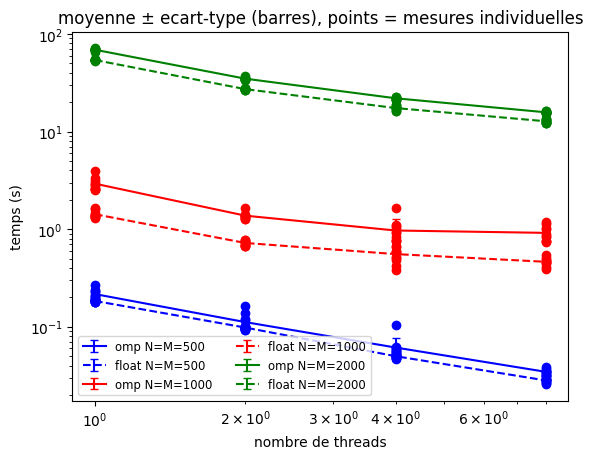

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

color_size = {500: "blue", 1000: "red", 2000: "green"}
version_linestyle = {"omp": "solid", "float": "dashed", "half": "dotted"}

df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie4_matrices')
# on ignore les executions de test (N, M, P differents) ecrites dans le meme fichier
df = df[df['N'].isin(color_size.keys()) & (df['N'] == df['M']) & (df['N'] == df['P'])]
versions_plot = ['omp', 'float']

for N in sorted(df['N'].unique()):
    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df[(df['N'] == N) & (df['version'] == version)]
        if df_plot.empty:
            continue

        keys = ['N', 'M', 'version', 'nbcore']
        mean_stats = df_plot.groupby(keys).mean(numeric_only=True).reset_index()
        std_stats = df_plot.groupby(keys).std(numeric_only=True).reset_index()

        plt.errorbar(mean_stats['nbcore'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                     linestyle=linestyle, color=color_size[N], label=f"{version} N=M={N}")
        plt.scatter(df_plot['nbcore'], df_plot['runtime'], color=color_size[N])

plt.yscale('log')
plt.xscale('log')
plt.xlabel('nombre de threads')
plt.ylabel('temps (s)')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Strong Scaling

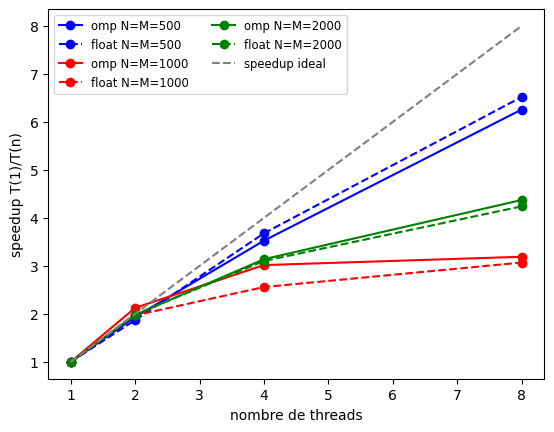

In [ ]:
fig_speedup = plt.figure()

for N in sorted(df['N'].unique()):
    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df[(df['N'] == N) & (df['version'] == version)]
        mean_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).mean(numeric_only=True).reset_index().sort_values('nbcore')
        if 1 not in mean_stats['nbcore'].values:
            continue

        t1 = mean_stats[mean_stats['nbcore'] == 1]['runtime'].values[0]
        speedup = t1 / mean_stats['runtime']

        plt.plot(mean_stats['nbcore'], speedup, linestyle=linestyle, color=color_size[N],
                 marker='o', label=f"{version} N=M={N}")

plt.plot([1, 2, 4, 8], [1, 2, 4, 8], linestyle='--', color='gray', label='speedup ideal')
plt.xlabel('nombre de threads')
plt.ylabel('speedup T(1)/T(n)')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Performance en mflops

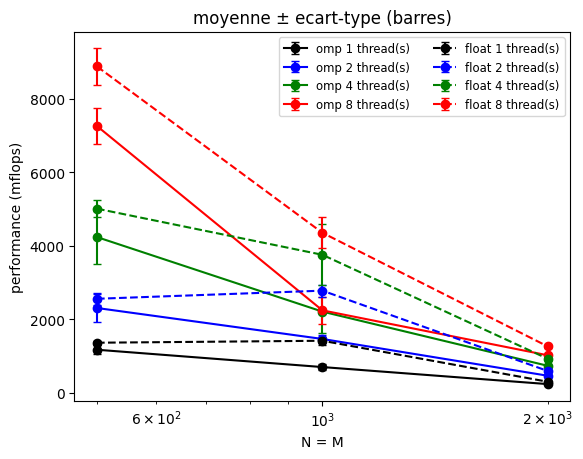

In [ ]:
color_core = {1: "black", 2: "blue", 4: "green", 8: "red"}

for version, linestyle in version_linestyle.items():
    if version not in versions_plot:
        continue
    df_v = df[df['version'] == version]
    for ncore in sorted(df_v['nbcore'].unique()):
        df_plot = df_v[df_v['nbcore'] == ncore]
        mean_stats = df_plot.groupby(['N', 'M']).mean(numeric_only=True).reset_index().sort_values('N')
        std_stats = df_plot.groupby(['N', 'M']).std(numeric_only=True).reset_index().sort_values('N')

        plt.errorbar(mean_stats['N'], mean_stats['mflops'], yerr=std_stats['mflops'], capsize=3,
                     linestyle=linestyle, color=color_core[ncore], marker='o', label=f"{version} {ncore} thread(s)")

plt.xscale('log')
plt.xlabel('N = M')
plt.ylabel('performance (mflops)')
plt.title('moyenne ± ecart-type (barres)')
plt.legend(fontsize='small', ncol=2)
plt.show()

In [ ]:
A, B, M, n = tableaux_part4(df4, 'float')
a = df4[(df4.version == 'omp') & (df4.N == df4.M) & (df4.N == df4.P)].groupby(['N', 'nbcore']).runtime.mean()
f = df4[(df4.version == 'float') & (df4.N == df4.M) & (df4.N == df4.P)].groupby(['N', 'nbcore']).runtime.mean()
R = "| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |\n|---|---|---|---|---|\n"
for N in sorted(df4['N'].unique()):
    if (N, 1) in f.index and (N, 1) in a.index:
        R += f"| {N} |" + "".join(f" {f[(N, c)] / a[(N, c)]:.2f} |" for c in [1, 2, 4, 8]) + "\n"
display(Markdown(f"**float : temps moyen ± écart-type (s), {n} exécutions par configuration**\n\n{A}\n"
                 f"**Speedup T(1)/T(n)**\n\n{B}\n"
                 f"**Performance moyenne (mflops)**\n\n{M}\n"
                 f"**Rapport des temps float / double** (inférieur à 1 : float plus rapide)\n\n{R}"))

**float : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 0.184 ± 0.005 | 0.098 ± 0.007 | 0.050 ± 0.002 | 0.028 ± 0.002 |
| 1000 | 1.42 ± 0.112 | 0.722 ± 0.043 | 0.555 ± 0.119 | 0.463 ± 0.045 |
| 2000 | 54.0 ± 0.795 | 27.2 ± 0.286 | 17.4 ± 0.955 | 12.7 ± 0.406 |

**Speedup T(1)/T(n)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1.00 | 1.87 | 3.68 | 6.52 |
| 1000 | 1.00 | 1.97 | 2.56 | 3.07 |
| 2000 | 1.00 | 1.99 | 3.10 | 4.24 |

**Performance moyenne (mflops)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1361 | 2558 | 5014 | 8889 |
| 1000 | 1414 | 2779 | 3757 | 4356 |
| 2000 | 296 | 589 | 922 | 1258 |

**Rapport des temps float / double** (inférieur à 1 : float plus rapide)

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 0.85 | 0.88 | 0.81 | 0.82 |
| 1000 | 0.49 | 0.53 | 0.57 | 0.51 |
| 2000 | 0.78 | 0.78 | 0.79 | 0.81 |


### Question 4.8 - Discussion (float)

Voici les mesures pour `float` (moyenne ± écart-type).

**float : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 0.184 ± 0.005 | 0.098 ± 0.007 | 0.050 ± 0.002 | 0.028 ± 0.002 |
| 1000 | 1.42 ± 0.112 | 0.722 ± 0.043 | 0.555 ± 0.119 | 0.463 ± 0.045 |
| 2000 | 54.0 ± 0.795 | 27.2 ± 0.286 | 17.4 ± 0.955 | 12.7 ± 0.406 |

**Speedup T(1)/T(n)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1.00 | 1.87 | 3.68 | 6.52 |
| 1000 | 1.00 | 1.97 | 2.56 | 3.07 |
| 2000 | 1.00 | 1.99 | 3.10 | 4.24 |

**Performance moyenne (mflops)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1361 | 2558 | 5014 | 8889 |
| 1000 | 1414 | 2779 | 3757 | 4356 |
| 2000 | 296 | 589 | 922 | 1258 |

**Rapport des temps float / double** (inférieur à 1 : float plus rapide)

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 0.85 | 0.88 | 0.81 | 0.82 |
| 1000 | 0.49 | 0.53 | 0.57 | 0.51 |
| 2000 | 0.78 | 0.78 | 0.79 | 0.81 |


Float est plus rapide que double à toutes les tailles, mais l'écart varie beaucoup. À 1 thread, le temps de float vaut 0.85, 0.49 et 0.78 fois celui de double pour N = 500, 1000 et 2000. Les rapports restent proches avec 2, 4 et 8 threads (0.81 à 0.88 à N = 500, 0.51 à 0.57 à N = 1000 et 0.78 à 0.81 à N = 2000).

Le gain approche un facteur 2 seulement à N = 1000. Une explication possible : les trois matrices occupent 12 Mo en float contre 24 Mo en double, ce qui est à peu près la taille du cache L3 (12 Mo) et pourrait leur permettre d'y tenir, alors que ce n'est pas le cas en double. À N = 500, tout tient dans le cache dans les deux cas et le gain reste modeste (15 à 19 %). À N = 2000, rien ne tient dans le cache et le gain reste d'environ 20 %.

Le speedup en fonction du nombre de threads est très proche de celui de double (6.52, 3.07 et 4.24 à 8 threads contre 6.26, 3.19 et 4.37). Le passage à float ne change pas la façon dont le calcul se répartit entre les threads, il réduit surtout le temps de chaque produit.

### Question 4.9 - Passage de double à half

Le code est celui de la 4.5 avec le type des matrices changé de `float` à `half` (`half_float::half` de `half.hpp`, 16 bits, soit 2 octets par élément).
- Les matrices `A`, `B`, `C` et l'accumulateur `tmp` sont des `half`, et les constantes sont converties avec `half(...)`. Les variables de vérification restent en `double`.
- Le processeur n'a pas d'instruction de calcul en `half`. La bibliothèque convertit en `float`, calcule, puis reconvertit à chaque opération.
- Le `half` n'a qu'environ 3 chiffres décimaux. Le seuil d'erreur relative maximale passe donc de 1e-3 à 5e-2.
- La plus grande valeur représentable en `half` est 65 504. Avec N = M = P, les valeurs attendues valent environ 17 x N (environ 34 000 pour N = 2000) et restent en dessous.
- Le nom de version dans la feuille `partie4_matrices` est `half`.

In [ ]:
from pathlib import Path

Path("src/4_9_matrix_mul_half.cpp").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <omp.h>
#include <fstream>
#include <cmath>
#include "half.hpp"
using half_float::half;


#define AVAL 3.14f
#define BVAL 5.42f
#define TOL  0.05

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
	int nbthreads = omp_get_max_threads();       // nombre de threads
	int i,j,k;
	half *A, *B, *C;
	double cval, err, maxrel;
    double dN, dM, dP, mflops;


    
    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-nbthreads" ) == 0 ) ) {
            nbthreads = atoi( argv[ ++i ] );
            omp_set_num_threads( nbthreads );
            printf( "  User nbthreads is %d\n", nbthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -C <int>:              Number of threads (default: max available)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }
      
	
      A = (half *)malloc(Ndim*Pdim*sizeof(half));
      B = (half *)malloc(Pdim*Mdim*sizeof(half));
      C = (half *)malloc(Ndim*Mdim*sizeof(half));

	/* Initialize matrices */

	for (i=0; i<Ndim; i++)
		for (j=0; j<Pdim; j++)
			*(A+(i*Ndim+j)) = half(AVAL);

	for (i=0; i<Pdim; i++)
		for (j=0; j<Mdim; j++)
			*(B+(i*Pdim+j)) = half(BVAL);

	for (i=0; i<Ndim; i++)
		for (j=0; j<Mdim; j++)
			*(C+(i*Ndim+j)) = half(0.0f);

	/* Do the matrix product */
    
    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );
    
    #pragma omp parallel for
    for (int i=0; i<Ndim; i++){
		for (int j=0; j<Mdim; j++){
			half tmp = half(0.0f);
			for(int k=0;k<Pdim;k++){
				/* C(i,j) = sum(over k) A(i,k) * B(k,j) */
				tmp += *(A+(i*Ndim+k)) *  *(B+(k*Pdim+j));
			}
			*(C+(i*Ndim+j)) = tmp;
		}
	}
	/* Check the answer */


    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );
                
	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 2.0 * dN * dN * dN/(1000000.0* time);
 
	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_part4.csv", std::ios::app) << "half," << nbthreads << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = (double)Pdim * 3.14 * 5.42;
	maxrel = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = fabs( (double)(float)*(C+i*Ndim+j) - cval ) / cval;
			if (err > maxrel) maxrel = err;
		}
	}

	if (maxrel > TOL)
		printf("\n Errors in multiplication");
	else
		printf("\n Hey, it worked");


	printf("\n all done \n");
}
""")

In [ ]:
!g++ -o bin/4_9_matrix_mul_half src/4_9_matrix_mul_half.cpp -fopenmp -O3 -march=native

In [ ]:
!.\bin\4_9_matrix_mul_half.exe -C 4 -N 300 -M 300 -P 300

### Question 4.10 - Évaluation de performance (half)

Mêmes tailles et mêmes nombres de threads qu'en 4.2 et 4.6, avec 10 répétitions. Les résultats s'ajoutent à la feuille `partie4_matrices` du classeur (elle n'est pas effacée ici).

In [ ]:
nettoyer_csv("partie4_matrices")

sizes = [500, 1000, 2000]
nb_core = [1, 2, 4, 8]

for n in sizes:
    for ncore in nb_core:
        for repeat in range(NB_REPETITIONS - deja_faites("partie4_matrices", "half", ncore, n)):
            args = ("./bin/4_9_matrix_mul_half.exe", "-C", str(ncore), "-N", str(n), "-M", str(n), "-P", str(n))
            popen = subprocess.Popen(args, stdout=subprocess.PIPE)
            popen.wait()
        fusionner("partie4_matrices")

### Question 4.11 - Figures de performance (half)

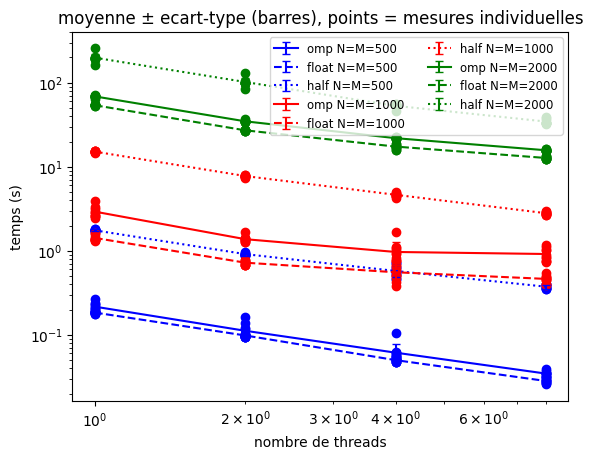

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

color_size = {500: "blue", 1000: "red", 2000: "green"}
version_linestyle = {"omp": "solid", "float": "dashed", "half": "dotted"}

df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie4_matrices')
# on ignore les executions de test (N, M, P differents) ecrites dans le meme fichier
df = df[df['N'].isin(color_size.keys()) & (df['N'] == df['M']) & (df['N'] == df['P'])]
versions_plot = ['omp', 'float', 'half']

for N in sorted(df['N'].unique()):
    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df[(df['N'] == N) & (df['version'] == version)]
        if df_plot.empty:
            continue

        keys = ['N', 'M', 'version', 'nbcore']
        mean_stats = df_plot.groupby(keys).mean(numeric_only=True).reset_index()
        std_stats = df_plot.groupby(keys).std(numeric_only=True).reset_index()

        plt.errorbar(mean_stats['nbcore'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                     linestyle=linestyle, color=color_size[N], label=f"{version} N=M={N}")
        plt.scatter(df_plot['nbcore'], df_plot['runtime'], color=color_size[N])

plt.yscale('log')
plt.xscale('log')
plt.xlabel('nombre de threads')
plt.ylabel('temps (s)')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Strong Scaling

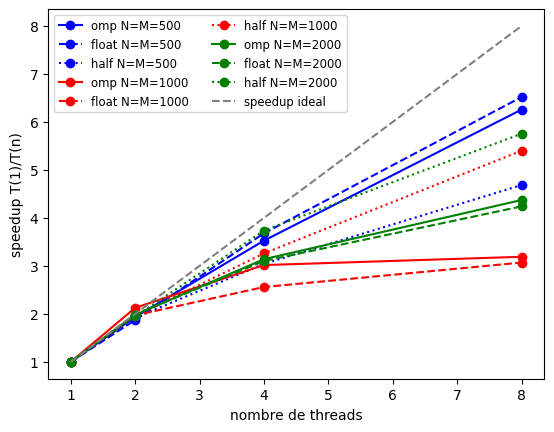

In [ ]:
fig_speedup = plt.figure()

for N in sorted(df['N'].unique()):
    for version, linestyle in version_linestyle.items():
        if version not in versions_plot:
            continue
        df_plot = df[(df['N'] == N) & (df['version'] == version)]
        mean_stats = df_plot.groupby(['N', 'M', 'version', 'nbcore']).mean(numeric_only=True).reset_index().sort_values('nbcore')
        if 1 not in mean_stats['nbcore'].values:
            continue

        t1 = mean_stats[mean_stats['nbcore'] == 1]['runtime'].values[0]
        speedup = t1 / mean_stats['runtime']

        plt.plot(mean_stats['nbcore'], speedup, linestyle=linestyle, color=color_size[N],
                 marker='o', label=f"{version} N=M={N}")

plt.plot([1, 2, 4, 8], [1, 2, 4, 8], linestyle='--', color='gray', label='speedup ideal')
plt.xlabel('nombre de threads')
plt.ylabel('speedup T(1)/T(n)')
plt.legend(fontsize='small', ncol=2)
plt.show()

#### Performance en mflops

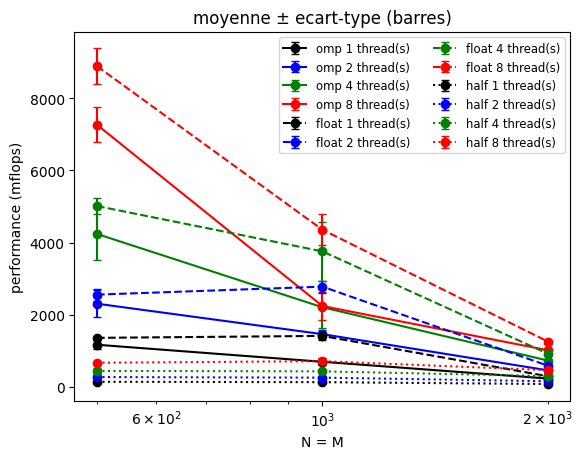

In [ ]:
color_core = {1: "black", 2: "blue", 4: "green", 8: "red"}

for version, linestyle in version_linestyle.items():
    if version not in versions_plot:
        continue
    df_v = df[df['version'] == version]
    for ncore in sorted(df_v['nbcore'].unique()):
        df_plot = df_v[df_v['nbcore'] == ncore]
        mean_stats = df_plot.groupby(['N', 'M']).mean(numeric_only=True).reset_index().sort_values('N')
        std_stats = df_plot.groupby(['N', 'M']).std(numeric_only=True).reset_index().sort_values('N')

        plt.errorbar(mean_stats['N'], mean_stats['mflops'], yerr=std_stats['mflops'], capsize=3,
                     linestyle=linestyle, color=color_core[ncore], marker='o', label=f"{version} {ncore} thread(s)")

plt.xscale('log')
plt.xlabel('N = M')
plt.ylabel('performance (mflops)')
plt.title('moyenne ± ecart-type (barres)')
plt.legend(fontsize='small', ncol=2)
plt.show()

In [ ]:
df4 = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie4_matrices')
A, B, M, n = tableaux_part4(df4, 'half')
grille = (df4['N'] == df4['M']) & (df4['N'] == df4['P'])
t = {v: df4[(df4.version == v) & grille].groupby(['N', 'nbcore']).runtime.mean() for v in ['omp', 'float', 'half']}
def rapport(num, den):
    h = "| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |\n|---|---|---|---|---|\n"
    for N in sorted(df4.loc[grille, 'N'].unique()):
        h += f"| {N} |" + "".join(f" {t[num][(N, c)] / t[den][(N, c)]:.1f} |" for c in [1, 2, 4, 8]) + "\n"
    return h
display(Markdown(f"**half : temps moyen ± écart-type (s), {n} exécutions par configuration**\n\n{A}\n"
                 f"**Speedup T(1)/T(n)**\n\n{B}\n"
                 f"**Performance moyenne (mflops)**\n\n{M}\n"
                 f"**Rapport des temps half / float**\n\n{rapport('half', 'float')}\n"
                 f"**Rapport des temps half / double**\n\n{rapport('half', 'omp')}"))

**half : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1.75 ± 0.046 | 0.913 ± 0.033 | 0.576 ± 0.094 | 0.374 ± 0.018 |
| 1000 | 15.1 ± 0.302 | 7.76 ± 0.186 | 4.64 ± 0.213 | 2.80 ± 0.082 |
| 2000 | 199 ± 23.4 | 102 ± 11.5 | 53.2 ± 2.55 | 34.5 ± 2.52 |

**Speedup T(1)/T(n)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1.00 | 1.92 | 3.04 | 4.68 |
| 1000 | 1.00 | 1.95 | 3.26 | 5.40 |
| 2000 | 1.00 | 1.95 | 3.74 | 5.75 |

**Performance moyenne (mflops)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 143 | 274 | 445 | 670 |
| 1000 | 132 | 258 | 432 | 714 |
| 2000 | 81 | 158 | 301 | 465 |

**Rapport des temps half / float**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 9.5 | 9.3 | 11.5 | 13.3 |
| 1000 | 10.6 | 10.7 | 8.4 | 6.1 |
| 2000 | 3.7 | 3.8 | 3.1 | 2.7 |

**Rapport des temps half / double**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 8.1 | 8.2 | 9.4 | 10.8 |
| 1000 | 5.2 | 5.6 | 4.8 | 3.1 |
| 2000 | 2.9 | 2.9 | 2.4 | 2.2 |


### Question 4.12 - Discussion (half)

Voici les mesures pour `half` (moyenne ± écart-type).

**half : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1.75 ± 0.046 | 0.913 ± 0.033 | 0.576 ± 0.094 | 0.374 ± 0.018 |
| 1000 | 15.1 ± 0.302 | 7.76 ± 0.186 | 4.64 ± 0.213 | 2.80 ± 0.082 |
| 2000 | 199 ± 23.4 | 102 ± 11.5 | 53.2 ± 2.55 | 34.5 ± 2.52 |

**Speedup T(1)/T(n)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 1.00 | 1.92 | 3.04 | 4.68 |
| 1000 | 1.00 | 1.95 | 3.26 | 5.40 |
| 2000 | 1.00 | 1.95 | 3.74 | 5.75 |

**Performance moyenne (mflops)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 143 | 274 | 445 | 670 |
| 1000 | 132 | 258 | 432 | 714 |
| 2000 | 81 | 158 | 301 | 465 |

**Rapport des temps half / float**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 9.5 | 9.3 | 11.5 | 13.3 |
| 1000 | 10.6 | 10.7 | 8.4 | 6.1 |
| 2000 | 3.7 | 3.8 | 3.1 | 2.7 |

**Rapport des temps half / double**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 500 | 8.1 | 8.2 | 9.4 | 10.8 |
| 1000 | 5.2 | 5.6 | 4.8 | 3.1 |
| 2000 | 2.9 | 2.9 | 2.4 | 2.2 |

À ma grande surprise half est beaucoup plus lent que float et double. À 1 thread, il est 9.5 et 10.6 fois plus lent que float pour N = 500 et 1000 (8.1 et 5.2 fois plus lent que double), et sa performance (143 et 132 mflops) est très inférieure à celle de float (1361 et 1414 mflops). Cela pourrait s'expliquer par la nécessité de passer par la bibliothèque `half.hpp` pour convertir en float, calculer, puis reconvertir à chaque opération (le processeur n'a pas d'instruction de calcul en half).

À N = 2000, l'écart avec float se réduit (2.7 à 3.8 fois plus lent). Une explication possible est que float et double sont freinés par la mémoire à cette taille (voir 4.4 et 4.8), alors que half l'est moins car les trois matrices en half occupent 24 Mo, contre 48 Mo en float et 96 Mo en double.

Le speedup (le gain de temps par rapport à 1 thread) de half est meilleur que celui de float pour N = 1000 et 2000, mais pas pour N = 500. À 8 threads, il vaut 4.7, 5.4 et 5.75 pour half (N = 500, 1000 et 2000), contre 6.52, 3.07 et 4.24 pour float.

Pour N = 1000 et 2000, une explication possible est que float est limité par la mémoire (les threads se disputent l'accès aux données), alors que half passe son temps à calculer (à cause des conversions), ce qui laisse plus de place aux threads supplémentaires. Pour N = 500, tout tient dans le cache et la mémoire ne gêne pas float. Half reste alors à 4.7, peut-être parce que le calcul est limité par les 6 cœurs physiques de la machine (donc un speedup limité à 6).

La précision de half est médiocre pour cette somme. Un nombre half ne garde qu'environ 3 chiffres significatifs. Au-delà de 16 384, l'écart entre deux valeurs représentables est de 16, alors que les termes ajoutés valent environ 17 : chaque addition est donc arrondie grossièrement et les erreurs s'accumulent. Pour cette raison, le seuil d'erreur relative du test a dû être relâché de 1e-3 (float) à 5e-2. 

Conclusion : sur cette machine, half n'apporte aucun gain de temps et dégrade la précision. Seule la charge sur la mémoire est réduite.

## 5. Chaining Matrix Multiplication

### Question 5.1 - Implémentation parallèle du workflow

4 produits indépendants (AB, CD, EF, GH), puis 2 produits (ABCD, EFGH), puis le produit final. Cela fait 7 produits, et les produits d'un même niveau ne dépendent pas les uns des autres.
- Chaque produit est une tâche OpenMP (`#pragma omp task`), exécutée par un thread libre. `#pragma omp single` fait qu'un seul thread crée les tâches, et `#pragma omp taskwait` attend la fin d'un niveau avant de passer au suivant.
- Le produit est la boucle du code de la partie 4, mise dans une fonction `matmul` pour pouvoir l'appeler 7 fois. Elle est séquentielle, et ses variables sont locales à la fonction, donc privées à chaque appel.
- Le parallélisme décroît avec les niveaux (4, puis 2, puis 1 produit). Le dernier produit n'utilise qu'un seul thread.
- Les matrices sont carrées : N = M = P. Les 8 matrices d'entrée valent `AVAL`, donc chaque case du résultat vaut N^7 x AVAL^8. Le test porte sur l'erreur relative maximale (seuil 1e-9).
- Le nombre d'opérations est 7 x 2 x N^3 (mflops). Chaque exécution ajoute une ligne à la feuille `partie5_chaine` (version `chain`, threads, N, M, P, temps, mflops).

In [ ]:
from pathlib import Path

Path("src/5_1_matrix_chain.cpp").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>
#include <omp.h>
#include <fstream>
#include <cmath>

#define AVAL 3.14
#define BVAL 5.42
#define TOL  1e-9

void matmul(double *A, double *B, double *C, int Ndim, int Pdim, int Mdim)
{
    int i,j,k;
    double tmp;
    for (i=0; i<Ndim; i++){
        for (j=0; j<Mdim; j++){
            tmp = 0.0;
            for(k=0;k<Pdim;k++){
                tmp += *(A+(i*Ndim+k)) *  *(B+(k*Pdim+j));
            }
            *(C+(i*Ndim+j)) = tmp;
        }
    }
}

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
	int nbthreads = omp_get_max_threads();       // nombre de threads
	int i,j;
	double *in[8];                                 // A, B, C, D, E, F, G, H
	double *AB, *CD, *EF, *GH, *ABCD, *EFGH, *R;
	double cval, err, maxrel;
    double dN, dM, dP, mflops;



    
    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-C" ) == 0 ) || ( strcmp( argv[ i ], "-nbthreads" ) == 0 ) ) {
            nbthreads = atoi( argv[ ++i ] );
            omp_set_num_threads( nbthreads );
            printf( "  User nbthreads is %d\n", nbthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -C <int>:              Number of threads (default: max available)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }
      
	
    for (int m=0; m<8; m++) {
		in[m] = (double *)malloc((size_t)Ndim*Ndim*sizeof(double));
		for (long x=0; x<(long)Ndim*Ndim; x++)
			in[m][x] = AVAL;                   /* Initialize matrices */
	}
	AB   = (double *)malloc((size_t)Ndim*Ndim*sizeof(double));
	CD   = (double *)malloc((size_t)Ndim*Ndim*sizeof(double));
	EF   = (double *)malloc((size_t)Ndim*Ndim*sizeof(double));
	GH   = (double *)malloc((size_t)Ndim*Ndim*sizeof(double));
	ABCD = (double *)malloc((size_t)Ndim*Ndim*sizeof(double));
	EFGH = (double *)malloc((size_t)Ndim*Ndim*sizeof(double));
	R    = (double *)malloc((size_t)Ndim*Ndim*sizeof(double));


	/* Do the matrix product */
    
    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );
    
    #pragma omp parallel
    #pragma omp single
    {
        /* niveau 1 : 4 produits independants */
        #pragma omp task
        matmul(in[0], in[1], AB, Ndim, Pdim, Mdim);
        #pragma omp task
        matmul(in[2], in[3], CD, Ndim, Pdim, Mdim);
        #pragma omp task
        matmul(in[4], in[5], EF, Ndim, Pdim, Mdim);
        #pragma omp task
        matmul(in[6], in[7], GH, Ndim, Pdim, Mdim);
        #pragma omp taskwait

        /* niveau 2 : 2 produits independants */
        #pragma omp task
        matmul(AB, CD, ABCD, Ndim, Pdim, Mdim);
        #pragma omp task
        matmul(EF, GH, EFGH, Ndim, Pdim, Mdim);
        #pragma omp taskwait

        /* niveau 3 : le produit final */
        matmul(ABCD, EFGH, R, Ndim, Pdim, Mdim);
	}
	/* Check the answer */


    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );
                
	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 7.0 * 2.0 * dN * dN * dN/(1000000.0* time);
 
	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_part5.csv", std::ios::app) << "chain," << nbthreads << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = pow((double)Ndim, 7) * pow(AVAL, 8);
	maxrel = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = fabs( *(R+i*Ndim+j) - cval ) / cval;
			if (err > maxrel) maxrel = err;
		}
	}

	if (maxrel > TOL)
		printf("\n Errors in multiplication");
	else
		printf("\n Hey, it worked");

	printf("\n all done \n");
}
""")

In [ ]:
!g++ -o bin/5_1_matrix_chain src/5_1_matrix_chain.cpp -fopenmp -O3 -march=native

In [ ]:
!.\bin\5_1_matrix_chain.exe -C 4 -N 300 -M 300 -P 300

### Question 5.2 - Évaluation de performance

L'énoncé demande N et M de 1000 à 18000. Les matrices sont carrées, donc je donne la même valeur à N, M et P. Une exécution fait 7 produits de N^3 opérations : à 1 thread, N = 1000 prend environ 20 s et N = 2000 environ 8 minutes. La grille de l'énoncé est donc trop coûteuse avec 10 répétitions : le choix a été fait d'utiliser N = M = P parmi 250, 500 et 1000.

| N = M = P | nb_core | répétitions |
|---|---|---|
| 250, 500, 1000 | 1, 2, 4, 8 | 10 |

In [ ]:
nettoyer_csv("partie5_chaine")

sizes = [250, 500, 1000]
nb_core = [1, 2, 4, 8]

for n in sizes:
    for ncore in nb_core:
        for repeat in range(NB_REPETITIONS - deja_faites("partie5_chaine", "chain", ncore, n)):
            args = ("./bin/5_1_matrix_chain.exe", "-C", str(ncore), "-N", str(n), "-M", str(n), "-P", str(n))
            popen = subprocess.Popen(args, stdout=subprocess.PIPE)
            popen.wait()
        fusionner("partie5_chaine")

### Question 5.3 - Figures de performance

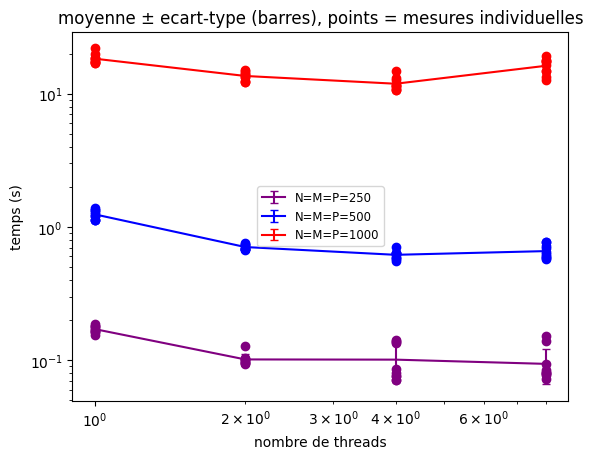

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

color_size = {250: "purple", 500: "blue", 1000: "red"}

df = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie5_chaine')
# on ignore les executions de test (N, M, P differents) ecrites dans le meme fichier
df = df[df['N'].isin(color_size.keys()) & (df['N'] == df['M']) & (df['N'] == df['P'])]

for N in sorted(df['N'].unique()):
    df_plot = df[df['N'] == N]
    keys = ['N', 'M', 'nbcore']
    mean_stats = df_plot.groupby(keys).mean(numeric_only=True).reset_index()
    std_stats = df_plot.groupby(keys).std(numeric_only=True).reset_index()

    plt.errorbar(mean_stats['nbcore'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                 color=color_size[N], label=f"N=M=P={N}")
    plt.scatter(df_plot['nbcore'], df_plot['runtime'], color=color_size[N])

plt.yscale('log')
plt.xscale('log')
plt.xlabel('nombre de threads')
plt.ylabel('temps (s)')
plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
plt.legend(fontsize='small')
plt.show()

#### Strong Scaling

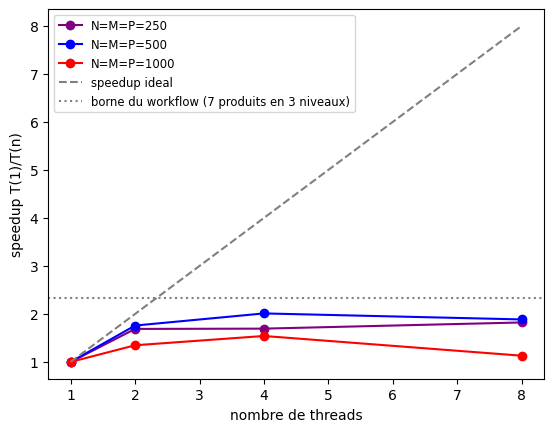

In [ ]:
fig_speedup = plt.figure()

for N in sorted(df['N'].unique()):
    df_plot = df[df['N'] == N]
    mean_stats = df_plot.groupby(['N', 'M', 'nbcore']).mean(numeric_only=True).reset_index().sort_values('nbcore')
    if 1 not in mean_stats['nbcore'].values:
        continue

    t1 = mean_stats[mean_stats['nbcore'] == 1]['runtime'].values[0]
    speedup = t1 / mean_stats['runtime']

    plt.plot(mean_stats['nbcore'], speedup, color=color_size[N], marker='o', label=f"N=M=P={N}")

plt.plot([1, 2, 4, 8], [1, 2, 4, 8], linestyle='--', color='gray', label='speedup ideal')
plt.axhline(7 / 3, linestyle=':', color='gray', label='borne du workflow (7 produits en 3 niveaux)')
plt.xlabel('nombre de threads')
plt.ylabel('speedup T(1)/T(n)')
plt.legend(fontsize='small')
plt.show()

#### Performance en mflops

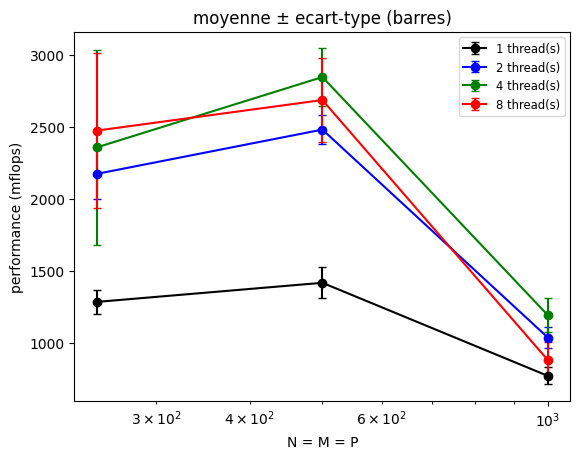

In [ ]:
color_core = {1: "black", 2: "blue", 4: "green", 8: "red"}

for ncore in sorted(df['nbcore'].unique()):
    df_plot = df[df['nbcore'] == ncore]
    mean_stats = df_plot.groupby(['N', 'M']).mean(numeric_only=True).reset_index().sort_values('N')
    std_stats = df_plot.groupby(['N', 'M']).std(numeric_only=True).reset_index().sort_values('N')

    plt.errorbar(mean_stats['N'], mean_stats['mflops'], yerr=std_stats['mflops'], capsize=3,
                 color=color_core[ncore], marker='o', label=f"{ncore} thread(s)")

plt.xscale('log')
plt.xlabel('N = M = P')
plt.ylabel('performance (mflops)')
plt.title('moyenne ± ecart-type (barres)')
plt.legend(fontsize='small')
plt.show()

In [ ]:
def tableaux_part5(df):
    d = df[(df['N'] == df['M']) & (df['N'] == df['P'])]
    g = d.groupby(['N', 'nbcore']).agg(t=('runtime', 'mean'), s=('runtime', 'std'), n=('runtime', 'count')).reset_index()
    ideal = {1: 1.0, 2: 7 / 4, 4: 7 / 3, 8: 7 / 3}    # 7 produits repartis en 3 niveaux (4, 2, 1)
    thr = [1, 2, 4, 8]
    h = "| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |\n|---|---|---|---|---|\n"
    A, B, P = h, h, h
    for N in sorted(g['N'].unique()):
        r = g[g.N == N].set_index('nbcore')
        A += f"| {N} |" + "".join(f" {_fmt(r.t[c])} ± {_fmt(r.s[c])} |" for c in thr) + "\n"
        B += f"| {N} |" + "".join(f" {r.t[1] / r.t[c]:.2f} |" for c in thr) + "\n"
        P += f"| {N} |" + "".join(f" {100 * r.t[1] / r.t[c] / ideal[c]:.0f} % |" for c in thr) + "\n"
    return A, B, P, int(g['n'].min())

df5 = pd.read_excel('donnees/mesures.xlsx', sheet_name='partie5_chaine')
A, B, P, n = tableaux_part5(df5)
display(Markdown(f"**Workflow par tâches : temps moyen ± écart-type (s), {n} exécutions par configuration**\n\n{A}\n"
                 f"**Speedup T(1)/T(n)**\n\n{B}\n"
                 f"**Part de la borne théorique** (2 threads : 7/4, 4 threads ou plus : 7/3)\n\n{P}"))

**Workflow par tâches : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 250 | 0.171 ± 0.011 | 0.101 ± 0.010 | 0.101 ± 0.032 | 0.094 ± 0.028 |
| 500 | 1.24 ± 0.095 | 0.706 ± 0.030 | 0.618 ± 0.045 | 0.659 ± 0.075 |
| 1000 | 18.3 ± 1.53 | 13.6 ± 0.976 | 11.9 ± 1.32 | 16.2 ± 2.14 |

**Speedup T(1)/T(n)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 250 | 1.00 | 1.69 | 1.69 | 1.82 |
| 500 | 1.00 | 1.76 | 2.01 | 1.89 |
| 1000 | 1.00 | 1.35 | 1.54 | 1.13 |

**Part de la borne théorique** (2 threads : 7/4, 4 threads ou plus : 7/3)

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 250 | 100 % | 96 % | 73 % | 78 % |
| 500 | 100 % | 100 % | 86 % | 81 % |
| 1000 | 100 % | 77 % | 66 % | 48 % |


### Question 5.4 - Discussion

Voici les mesures pour le workflow par tâches (moyenne ± écart-type).

**Workflow par tâches : temps moyen ± écart-type (s), 10 exécutions par configuration**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 250 | 0.171 ± 0.011 | 0.101 ± 0.010 | 0.101 ± 0.032 | 0.094 ± 0.028 |
| 500 | 1.24 ± 0.095 | 0.706 ± 0.030 | 0.618 ± 0.045 | 0.659 ± 0.075 |
| 1000 | 18.3 ± 1.53 | 13.6 ± 0.976 | 11.9 ± 1.32 | 16.2 ± 2.14 |

**Speedup T(1)/T(n)**

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 250 | 1.00 | 1.69 | 1.69 | 1.82 |
| 500 | 1.00 | 1.76 | 2.01 | 1.89 |
| 1000 | 1.00 | 1.35 | 1.54 | 1.13 |

**Part de la borne théorique** (2 threads : 7/4, 4 threads ou plus : 7/3)

| N = M = P | 1 thread | 2 threads | 4 threads | 8 threads |
|---|---|---|---|---|
| 250 | 100 % | 96 % | 73 % | 78 % |
| 500 | 100 % | 100 % | 86 % | 81 % |
| 1000 | 100 % | 77 % | 66 % | 48 % |

Le gain est limité par la structure du workflow : les 7 produits forment 3 niveaux (4, 2 puis 1 produit) et un produit s'exécute sur un seul thread. Si tous les produits durent le même temps, le speedup maximal est 7/4 = 1.75 avec 2 threads et 7/3 = 2.33 avec 4 threads ou plus (la ligne pointillée de la figure). Au-delà de 4 threads on ne peut donc rien gagner.

Mes mesures sont proches de cette borne aux petites tailles : à 2 threads, 1.69 (N = 250) et 1.76 (N = 500), soit 96 % et 100 % de 1.75, et 2.01 à 4 threads pour N = 500 (86 % de 2.33).

À N = 1000, ça s'effondre : 1.35, 1.54 et 1.13 à 2, 4 et 8 threads, et 8 threads sont plus lents que 4 (16.2 s contre 11.9 s). Plusieurs produits de 1000 x 1000 (8 Mo par matrice) tournent en même temps et leurs données dépassent largement le cache L3 de 12 Mo, donc la mémoire doit saturer. Les 6 cœurs physiques partagés par 8 threads n'aident sans doute pas.

La parallélisation par tâches est ici moins bonne qu'un simple `parallel for` dans chaque produit. D'après la partie 4, un produit de 1000 x 1000 prend 0.92 s à 8 threads avec `parallel for`, donc les 7 produits prendraient environ 6.4 s, contre 16.2 s mesurés avec les tâches (11.9 s à 4 threads). À N = 500, on aurait environ 0.24 s contre 0.66 s. C'est une estimation, car je n'ai pas exécuté cette version. Avec les tâches, le dernier produit n'utilise qu'un thread et le niveau 2 seulement deux, alors que `parallel for` utilise tous les threads pour chaque produit.

On pourrait combiner les deux (des tâches pour les produits indépendants et un `parallel for` dans chaque produit), mais je ne l'ai pas testé.

En résumé, la version par tâches apporte au mieux un facteur 2 sur ma machine, et elle perd en efficacité quand les matrices ne tiennent plus dans le cache.